In [3]:
STUDENT = "Muhammad Asad Mashood"
REG_NO = "FA23-BAI-039"
ROLL = REG_NO[-3:]
SEED = int(ROLL[-2:])
LAST_DIGIT = int(ROLL[-1])
HOG_CELL = 8 if LAST_DIGIT % 2 == 0 else 16
GRID = 4 if LAST_DIGIT <= 4 else 6

print(f"Student        : {STUDENT} ({REG_NO})")
print(f"Random seed    : {SEED}")
print(f"HOG cell size  : {HOG_CELL} x {HOG_CELL}")
print(f"SIFT grid size : {GRID} x {GRID} ({GRID * GRID} keypoints)")

Student        : Muhammad Asad Mashood (FA23-BAI-039)
Random seed    : 39
HOG cell size  : 16 x 16
SIFT grid size : 6 x 6 (36 keypoints)


# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images

**Computer Vision Lab** &nbsp;|&nbsp; Muhammad Asad Mashood &nbsp;|&nbsp; FA23-BAI-039

Registration number 039 gives seed **39**, HOG cell **16 x 16** (last digit 9 is odd) and a **6 x 6** SIFT grid (9 lies between 5 and 9).

Q1 to Q5 follow the lab sheet exactly. The **Bonus** section at the end goes beyond the sheet with a pretrained deep-feature pipeline, explainability maps and an interactive explorer.

In [4]:
!pip install medmnist

import hashlib
import warnings

import cv2
import matplotlib.pyplot as plt
import medmnist
import numpy as np
import pandas as pd
import skimage
import sklearn
from IPython.display import Markdown, display
from medmnist import BloodMNIST
from skimage import exposure
from skimage.feature import hog
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(SEED)

CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_PER_CLASS = {"train": 100, "val": 30, "test": 30}
FIT_SPLITS = ("train", "val")
IMG = 128
ORIENTATIONS = 9
BLOCK_CELLS = (2, 2)
C_GRID = [0.1, 1, 10]
ROT_DEG = 20
NOISE_SIGMA = 0.05
KP_SIZE = 32

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10})

print(
    f"numpy {np.__version__} | opencv {cv2.__version__} | scikit-image {skimage.__version__} | "
    f"scikit-learn {sklearn.__version__} | medmnist {medmnist.__version__}"
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]
numpy 2.1.3 | opencv 5.0.0 | scikit-image 0.25.2 | scikit-learn 1.6.1 | medmnist 3.0.2


# Q1. Data setup

In [5]:
raw = {split: BloodMNIST(split=split, download=True, size=64) for split in N_PER_CLASS}


def draw_subset(ds, n_per_class, rng):
    images, targets = ds.imgs, ds.labels.ravel()
    xs, ys, ids = [], [], []
    for new_label, class_id in enumerate(CLASS_IDS):
        pool = np.flatnonzero(targets == class_id)
        pick = rng.choice(pool, size=n_per_class, replace=False)
        xs.append(images[pick])
        ys.append(np.full(n_per_class, new_label))
        ids.append(pick)
    x, y, idx = np.concatenate(xs), np.concatenate(ys), np.concatenate(ids)
    order = rng.permutation(len(y))
    return x[order], y[order], idx[order]


rng = np.random.default_rng(SEED)
data = {split: draw_subset(raw[split], N_PER_CLASS[split], rng) for split in N_PER_CLASS}
rgb = {split: data[split][0] for split in data}
labels = {split: data[split][1] for split in data}
picked = {split: data[split][2] for split in data}


def to_gray(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return cv2.resize(g, (IMG, IMG), interpolation=cv2.INTER_LINEAR)


gray = {split: np.stack([to_gray(i) for i in rgb[split]]) for split in rgb}

for split in data:
    print(f"{split:<5} images {rgb[split].shape} | grayscale {gray[split].shape} | labels {labels[split].shape}")

counts = pd.DataFrame(
    {split: np.bincount(labels[split], minlength=len(CLASS_NAMES)) for split in data},
    index=CLASS_NAMES,
).T
counts["total"] = counts.sum(axis=1)
print()
print(counts)

100%|██████████| 156M/156M [03:35<00:00, 726kB/s]


train images (400, 64, 64, 3) | grayscale (400, 128, 128) | labels (400,)
val   images (120, 64, 64, 3) | grayscale (120, 128, 128) | labels (120,)
test  images (120, 64, 64, 3) | grayscale (120, 128, 128) | labels (120,)

       eosinophil  monocyte  neutrophil  platelet  total
train         100       100         100       100    400
val            30        30          30        30    120
test           30        30          30        30    120


images available per class before sampling:
            train  val  test
eosinophil   2181  312   624
monocyte      993  143   284
neutrophil   2330  333   666
platelet     1643  235   470


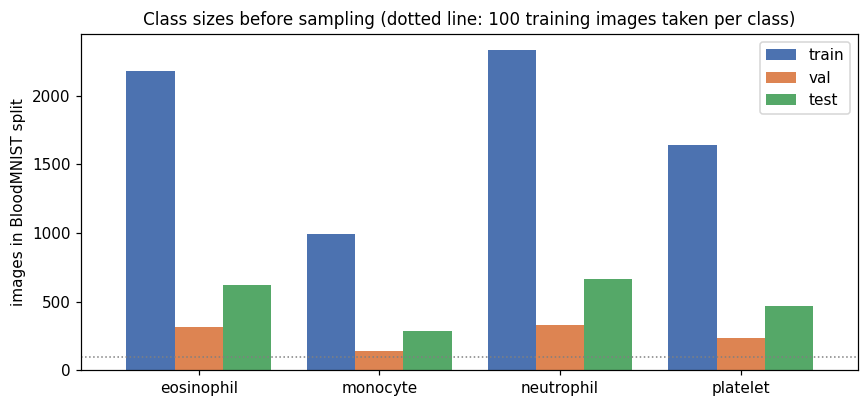

In [6]:
available = pd.DataFrame(
    {s: [int((raw[s].labels.ravel() == cid).sum()) for cid in CLASS_IDS] for s in N_PER_CLASS},
    index=CLASS_NAMES,
)
print("images available per class before sampling:")
print(available)

ax = available.plot(kind="bar", figsize=(8, 3.8), width=0.8, color=["#4c72b0", "#dd8452", "#55a868"])
ax.axhline(100, color="grey", ls=":", lw=1)
ax.set_ylabel("images in BloodMNIST split")
ax.set_title("Class sizes before sampling (dotted line: 100 training images taken per class)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

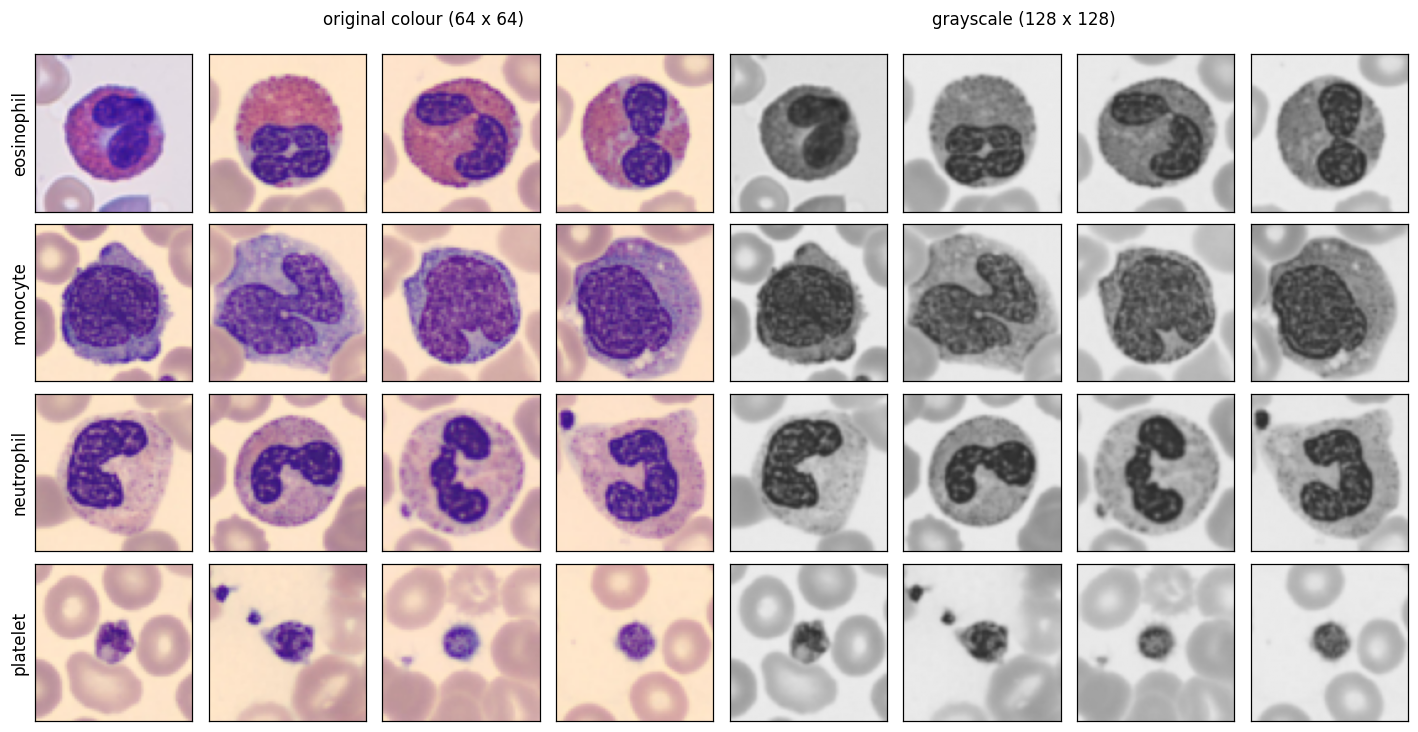

In [7]:
fig, axes = plt.subplots(4, 8, figsize=(13, 6.8))
for k, name in enumerate(CLASS_NAMES):
    picks = np.flatnonzero(labels["train"] == k)[:4]
    for j, i in enumerate(picks):
        axes[k, j].imshow(rgb["train"][i])
        axes[k, j + 4].imshow(gray["train"][i], cmap="gray", vmin=0, vmax=255)
    axes[k, 0].set_ylabel(name, fontsize=11)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
fig.text(0.30, 0.955, "original colour (64 x 64)", ha="center", fontsize=11)
fig.text(0.72, 0.955, "grayscale (128 x 128)", ha="center", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

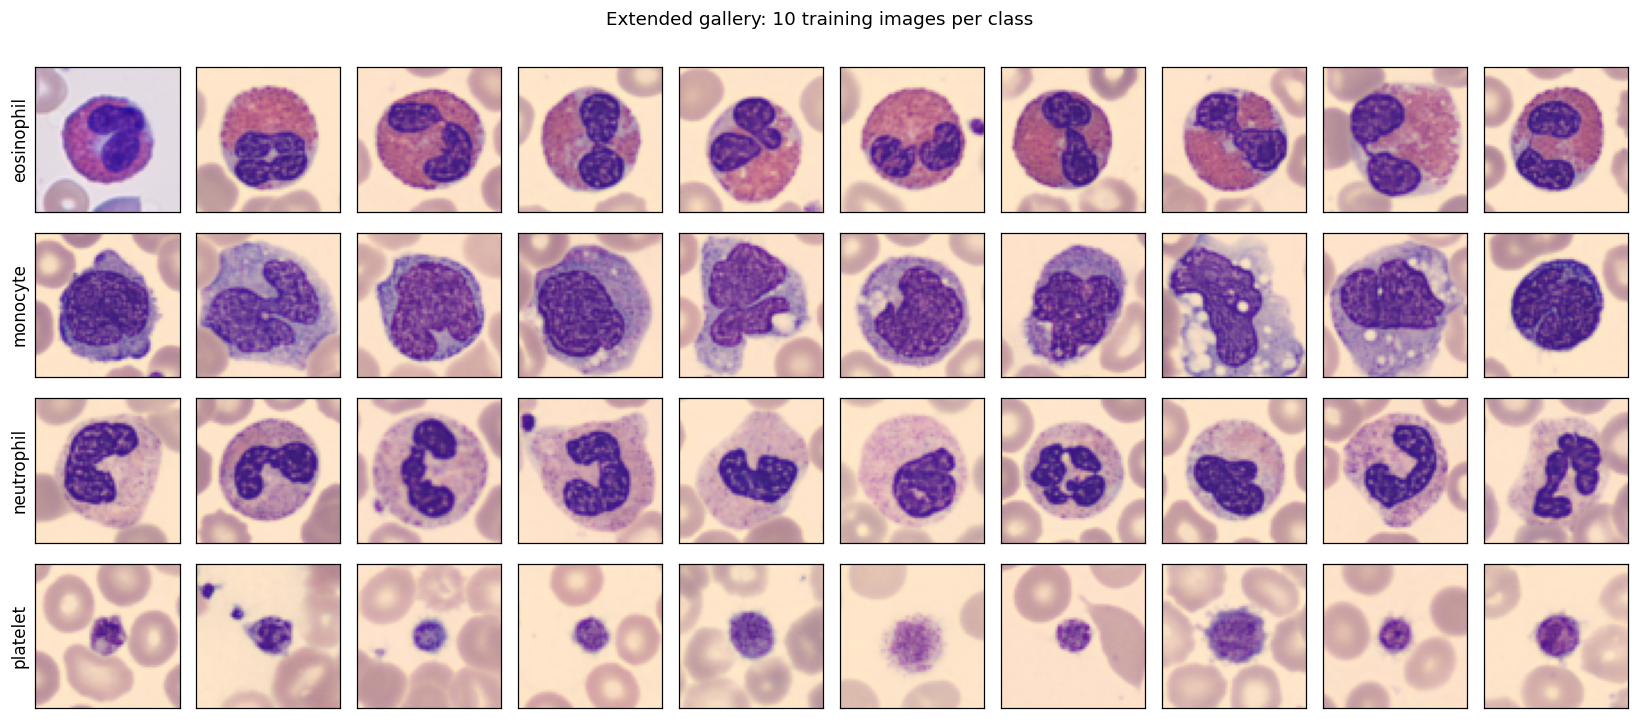

In [8]:
fig, axes = plt.subplots(4, 10, figsize=(15, 6.6))
for k, name in enumerate(CLASS_NAMES):
    for j, i in enumerate(np.flatnonzero(labels["train"] == k)[:10]):
        axes[k, j].imshow(rgb["train"][i])
        axes[k, j].set_xticks([])
        axes[k, j].set_yticks([])
    axes[k, 0].set_ylabel(name, fontsize=11)
fig.suptitle("Extended gallery: 10 training images per class", y=0.995)
plt.tight_layout()
plt.show()

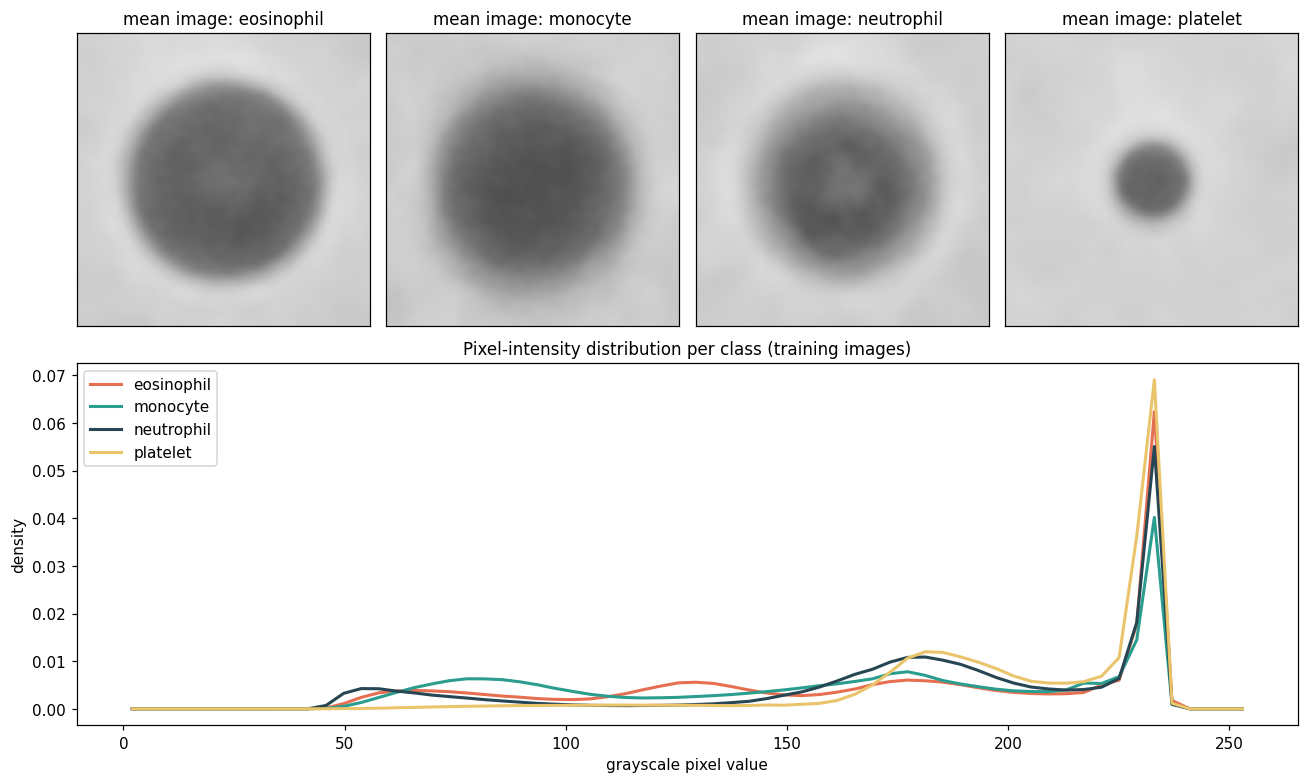

In [9]:
fig, axd = plt.subplot_mosaic([["m0", "m1", "m2", "m3"], ["h", "h", "h", "h"]], figsize=(12, 7.2), height_ratios=[1, 1.1])
palette = ["#e76f51", "#2a9d8f", "#264653", "#e9c46a"]
for k, name in enumerate(CLASS_NAMES):
    members = gray["train"][labels["train"] == k]
    axd[f"m{k}"].imshow(members.mean(axis=0), cmap="gray", vmin=0, vmax=255)
    axd[f"m{k}"].set_title(f"mean image: {name}")
    axd[f"m{k}"].set_xticks([])
    axd[f"m{k}"].set_yticks([])
    hist, edges = np.histogram(members.ravel(), bins=64, range=(0, 255), density=True)
    axd["h"].plot((edges[:-1] + edges[1:]) / 2, hist, color=palette[k], lw=2, label=name)
axd["h"].set_xlabel("grayscale pixel value")
axd["h"].set_ylabel("density")
axd["h"].set_title("Pixel-intensity distribution per class (training images)")
axd["h"].legend()
plt.tight_layout()
plt.show()

In [10]:
digest = {s: [hashlib.md5(i.tobytes()).hexdigest() for i in rgb[s]] for s in rgb}
split_pairs = [("train", "val"), ("train", "test"), ("val", "test")]
print("duplicate images inside each split:", {s: len(digest[s]) - len(set(digest[s])) for s in digest})
print("images shared across splits       :", {f"{a}/{b}": len(set(digest[a]) & set(digest[b])) for a, b in split_pairs})

duplicate images inside each split: {'train': 0, 'val': 0, 'test': 0}
images shared across splits       : {'train/val': 0, 'train/test': 0, 'val/test': 0}


# Q2. HOG + SVM

### Feature length by hand (cell 16 x 16)

- Cells per side: 128 / 16 = **8**, so the image holds 8 x 8 cells.
- A 2 x 2 block slides one cell at a time: 8 - 2 + 1 = **7** positions per side, so 7 x 7 = **49 blocks**.
- Each block stores 2 x 2 cells x 9 orientation bins = **36 values**.
- Feature length = 49 x 36 = **1764**.

In [11]:
HOG_KW = dict(
    orientations=ORIENTATIONS,
    pixels_per_cell=(HOG_CELL, HOG_CELL),
    cells_per_block=BLOCK_CELLS,
    block_norm="L2-Hys",
)


def hog_vec(img):
    return hog(img.astype(np.float32) / 255.0, feature_vector=True, **HOG_KW)


def hog_pic(img):
    _, vis = hog(img.astype(np.float32) / 255.0, visualize=True, **HOG_KW)
    return exposure.rescale_intensity(vis, in_range="image")


cells_per_side = IMG // HOG_CELL
blocks_per_side = cells_per_side - BLOCK_CELLS[0] + 1
expected_hog_len = blocks_per_side ** 2 * BLOCK_CELLS[0] * BLOCK_CELLS[1] * ORIENTATIONS

X_hog = {s: np.stack([hog_vec(i) for i in gray[s]]) for s in FIT_SPLITS}

print(f"cells per side {cells_per_side} | blocks per side {blocks_per_side} | by formula {expected_hog_len}")
print(f"extracted HOG feature length: {X_hog['train'].shape[1]} | matches formula: {X_hog['train'].shape[1] == expected_hog_len}")
print({s: X_hog[s].shape for s in X_hog})

cells per side 8 | blocks per side 7 | by formula 1764
extracted HOG feature length: 1764 | matches formula: True
{'train': (400, 1764), 'val': (120, 1764)}


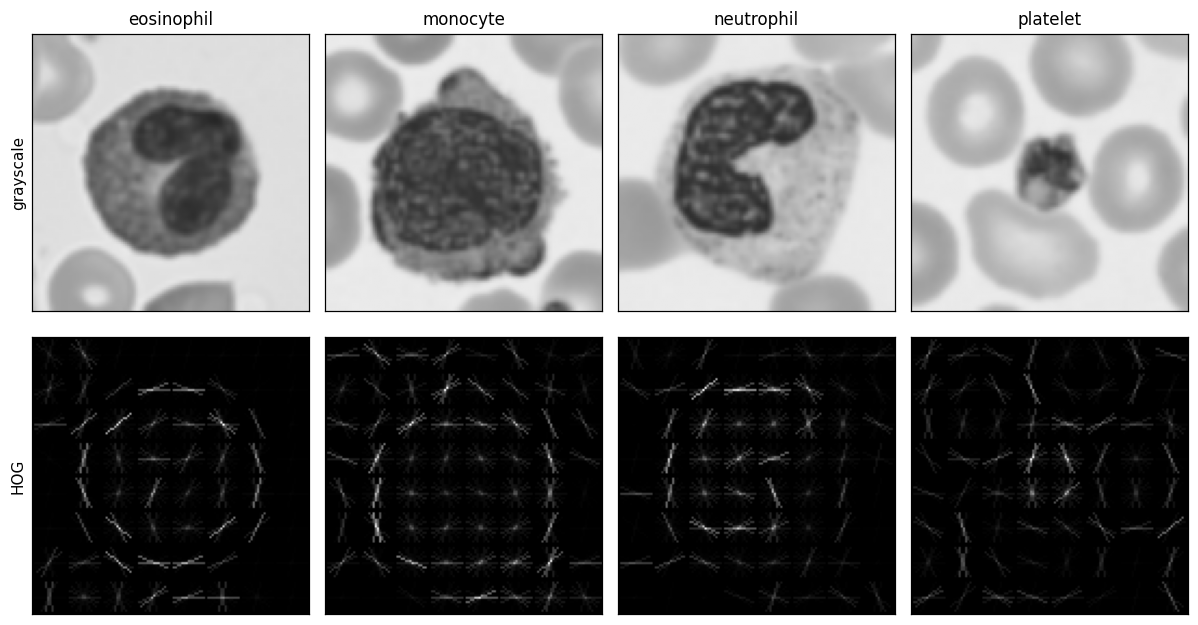

In [12]:
first_idx = [int(np.flatnonzero(labels["train"] == k)[0]) for k in range(len(CLASS_NAMES))]

fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for k, i in enumerate(first_idx):
    axes[0, k].imshow(gray["train"][i], cmap="gray", vmin=0, vmax=255)
    axes[0, k].set_title(CLASS_NAMES[k])
    axes[1, k].imshow(hog_pic(gray["train"][i]), cmap="gray")
axes[0, 0].set_ylabel("grayscale")
axes[1, 0].set_ylabel("HOG")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

   C  train_accuracy  val_accuracy
 0.1             1.0        0.7750
 1.0             1.0        0.7667
10.0             1.0        0.7667
selected C = 0.1 (highest validation accuracy, smallest C on ties)



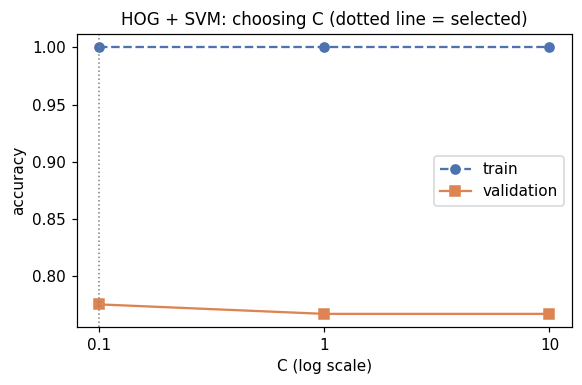

HOG + SVM (validation): accuracy = 0.7750 | macro-F1 = 0.7756
            precision  recall  f1-score  support
eosinophil      0.645   0.667     0.656     30.0
monocyte        0.727   0.800     0.762     30.0
neutrophil      0.741   0.667     0.702     30.0
platelet        1.000   0.967     0.983     30.0
macro avg       0.778   0.775     0.776    120.0


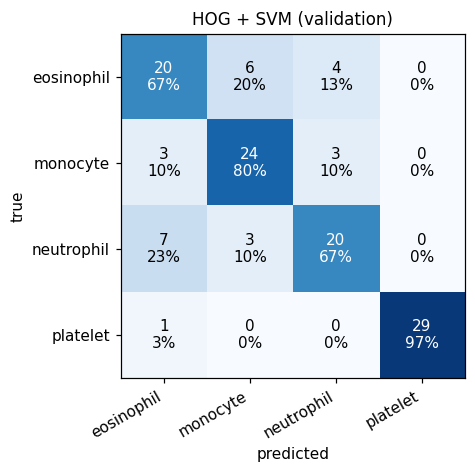

[[20  6  4  0]
 [ 3 24  3  0]
 [ 7  3 20  0]
 [ 1  0  0 29]]


In [13]:
def fit_with_validation(X_train, y_train, X_val, y_val, builder=None):
    build = builder or (lambda c: LinearSVC(C=c, dual=True, max_iter=100000, random_state=SEED))
    records, best_model, best_acc, best_c = [], None, -1.0, None
    for c in C_GRID:
        model = build(c).fit(X_train, y_train)
        val_acc = accuracy_score(y_val, model.predict(X_val))
        train_acc = accuracy_score(y_train, model.predict(X_train))
        records.append({"C": c, "train_accuracy": round(train_acc, 4), "val_accuracy": round(val_acc, 4)})
        if val_acc > best_acc:
            best_model, best_acc, best_c = model, val_acc, c
    return best_model, best_c, pd.DataFrame(records)


def plot_c_curve(table, selected_c, title):
    fig, ax = plt.subplots(figsize=(5.4, 3.6))
    ax.semilogx(table["C"], table["train_accuracy"], "o--", color="#4c72b0", label="train")
    ax.semilogx(table["C"], table["val_accuracy"], "s-", color="#dd8452", label="validation")
    ax.axvline(selected_c, color="grey", ls=":", lw=1)
    ax.set_xticks(C_GRID, [str(c) for c in C_GRID])
    ax.minorticks_off()
    ax.set_xlabel("C (log scale)")
    ax.set_ylabel("accuracy")
    ax.set_title(f"{title}: choosing C (dotted line = selected)")
    ax.legend()
    plt.tight_layout()
    plt.show()


def report(model, X, y_true, title):
    pred = model.predict(X)
    accuracy = accuracy_score(y_true, pred)
    f1 = f1_score(y_true, pred, average="macro")
    cm = confusion_matrix(y_true, pred, labels=range(len(CLASS_NAMES)))
    per_class = pd.DataFrame(
        classification_report(y_true, pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    ).T.round(3)
    print(f"{title}: accuracy = {accuracy:.4f} | macro-F1 = {f1:.4f}")
    print(per_class.loc[CLASS_NAMES + ["macro avg"], ["precision", "recall", "f1-score", "support"]].to_string())
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title)
    for r in range(cm.shape[0]):
        for c in range(cm.shape[1]):
            share = cm[r, c] / cm[r].sum()
            ax.text(c, r, f"{cm[r, c]}\n{share:.0%}", ha="center", va="center", color="white" if share > 0.5 else "black")
    plt.tight_layout()
    plt.show()
    return cm, accuracy, f1


hog_model, hog_C, hog_table = fit_with_validation(X_hog["train"], labels["train"], X_hog["val"], labels["val"])
print(hog_table.to_string(index=False))
print(f"selected C = {hog_C} (highest validation accuracy, smallest C on ties)")
print()
plot_c_curve(hog_table, hog_C, "HOG + SVM")
cm_hog, hog_val_acc, hog_val_f1 = report(hog_model, X_hog["val"], labels["val"], "HOG + SVM (validation)")
print(cm_hog)

# Q3. SIFT + SVM

### Standard SIFT detection on the training images

keypoints per image: mean 71.4 | min 7 | max 263
images with zero keypoints: 0 of 400


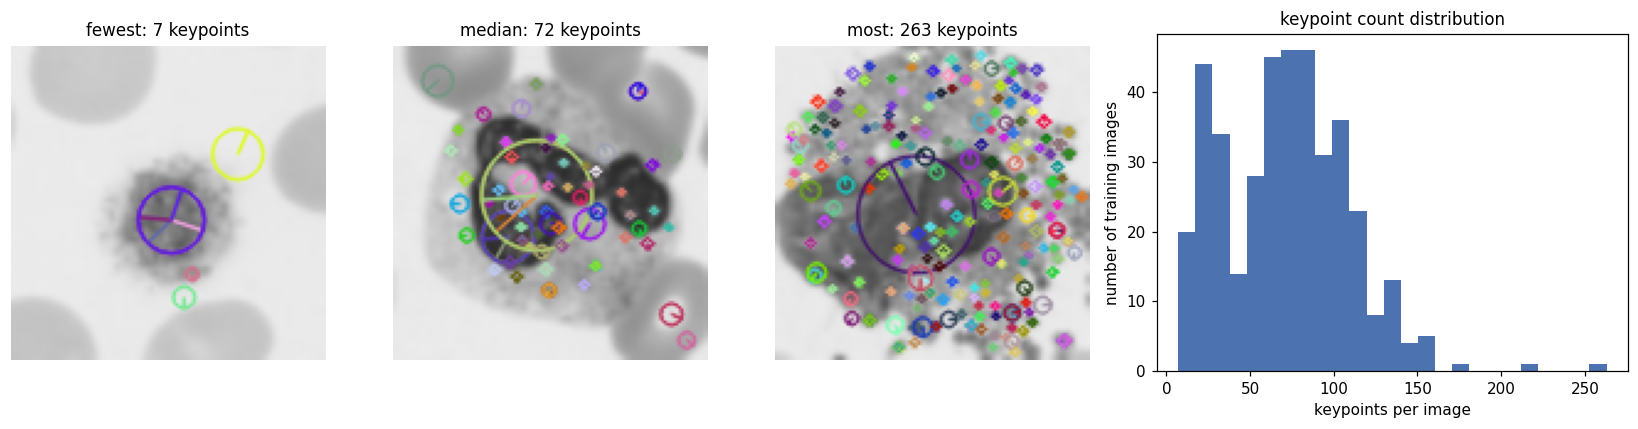

             mean  min  max
class                      
eosinophil   85.1   33  263
monocyte    100.6   16  213
neutrophil   74.3   36  178
platelet     25.6    7   74


In [14]:
sift = cv2.SIFT_create()
detected = [sift.detectAndCompute(img, None) for img in gray["train"]]
kp_counts = np.array([len(kps) for kps, _ in detected])

print(f"keypoints per image: mean {kp_counts.mean():.1f} | min {kp_counts.min()} | max {kp_counts.max()}")
print(f"images with zero keypoints: {int((kp_counts == 0).sum())} of {len(kp_counts)}")

order = np.argsort(kp_counts)
show = {"fewest": order[0], "median": order[len(order) // 2], "most": order[-1]}

fig, axes = plt.subplots(1, 4, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
for ax, (tag, i) in zip(axes, show.items()):
    vis = cv2.drawKeypoints(gray["train"][i], detected[i][0], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax.imshow(vis[..., ::-1])
    ax.set_title(f"{tag}: {kp_counts[i]} keypoints")
    ax.axis("off")
axes[3].hist(kp_counts, bins=25, color="#4c72b0")
axes[3].set_xlabel("keypoints per image")
axes[3].set_ylabel("number of training images")
axes[3].set_title("keypoint count distribution")
plt.tight_layout()
plt.show()

by_class = pd.DataFrame({"class": [CLASS_NAMES[k] for k in labels["train"]], "keypoints": kp_counts})
print(by_class.groupby("class")["keypoints"].agg(["mean", "min", "max"]).round(1))

**Why a varying keypoint count is a problem for an SVM:** an SVM needs every sample to be a vector of the same length, but standard SIFT returns one 128-value descriptor per keypoint, so images with different keypoint counts give feature vectors of different lengths that cannot be stacked into one matrix or compared dimension by dimension.

### Fixed grid of keypoints

Keypoint centres are placed at ((i + 0.5) x 128 / 6) on both axes, keypoint size is 32, and the keypoint angle is fixed to 0 so that every descriptor is computed in the same orientation. Each descriptor is divided by 512 to bring the values to a scale suited to the linear SVM.

- Grid points: 6 x 6 = **36**.
- Each SIFT descriptor has **128** values.
- Feature length = 36 x 128 = **4608**.

grid points 36 x 128 = 4608
extracted SIFT feature length: 4608 | matches formula: True
{'train': (400, 4608), 'val': (120, 4608)}


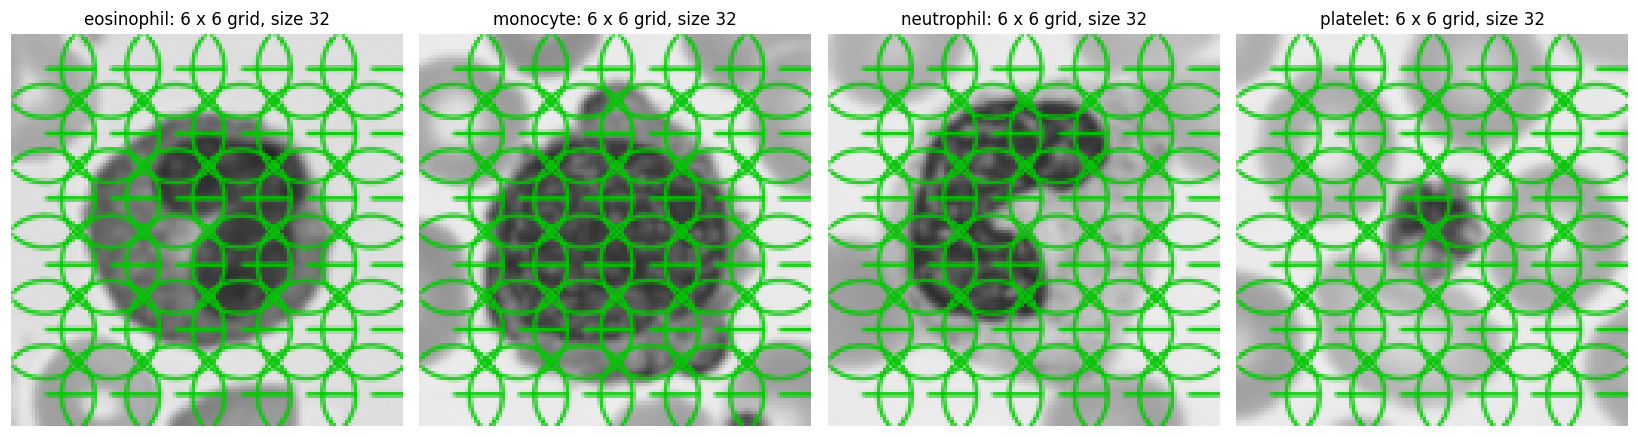

In [15]:
def grid_keypoints():
    step = IMG / GRID
    centres = (np.arange(GRID) + 0.5) * step
    return [cv2.KeyPoint(float(cx), float(cy), float(KP_SIZE), 0.0) for cy in centres for cx in centres]


GRID_KPS = grid_keypoints()


def sift_vec(img):
    _, des = sift.compute(img, GRID_KPS)
    return des.reshape(-1) / 512.0


expected_sift_len = GRID * GRID * 128
X_sift = {s: np.stack([sift_vec(i) for i in gray[s]]) for s in FIT_SPLITS}

print(f"grid points {GRID * GRID} x 128 = {expected_sift_len}")
print(f"extracted SIFT feature length: {X_sift['train'].shape[1]} | matches formula: {X_sift['train'].shape[1] == expected_sift_len}")
print({s: X_sift[s].shape for s in X_sift})

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for k, ax in enumerate(axes):
    overlay = cv2.drawKeypoints(
        gray["train"][first_idx[k]], GRID_KPS, None, color=(0, 200, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )
    ax.imshow(overlay[..., ::-1])
    ax.set_title(f"{CLASS_NAMES[k]}: {GRID} x {GRID} grid, size {KP_SIZE}")
    ax.axis("off")
plt.tight_layout()
plt.show()

   C  train_accuracy  val_accuracy
 0.1          0.8725        0.8167
 1.0          0.9725        0.8583
10.0          1.0000        0.8417
selected C = 1 (highest validation accuracy, smallest C on ties)



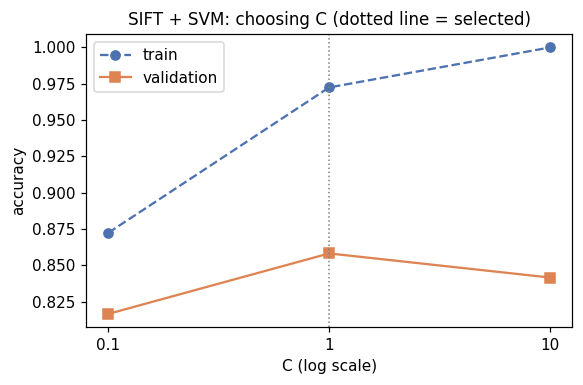

SIFT + SVM (validation): accuracy = 0.8583 | macro-F1 = 0.8560
            precision  recall  f1-score  support
eosinophil      0.769   0.667     0.714     30.0
monocyte        0.818   0.900     0.857     30.0
neutrophil      0.839   0.867     0.852     30.0
platelet        1.000   1.000     1.000     30.0
macro avg       0.857   0.858     0.856    120.0


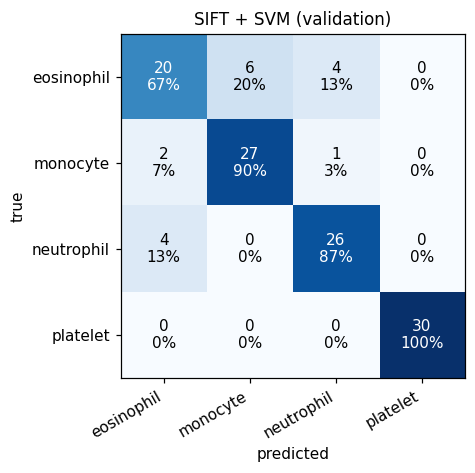

[[20  6  4  0]
 [ 2 27  1  0]
 [ 4  0 26  0]
 [ 0  0  0 30]]


In [16]:
sift_model, sift_C, sift_table = fit_with_validation(X_sift["train"], labels["train"], X_sift["val"], labels["val"])
print(sift_table.to_string(index=False))
print(f"selected C = {sift_C} (highest validation accuracy, smallest C on ties)")
print()
plot_c_curve(sift_table, sift_C, "SIFT + SVM")
cm_sift, sift_val_acc, sift_val_f1 = report(sift_model, X_sift["val"], labels["val"], "SIFT + SVM (validation)")
print(cm_sift)

            validation accuracy  macro-F1
HOG + SVM                0.7750    0.7756
SIFT + SVM               0.8583    0.8560


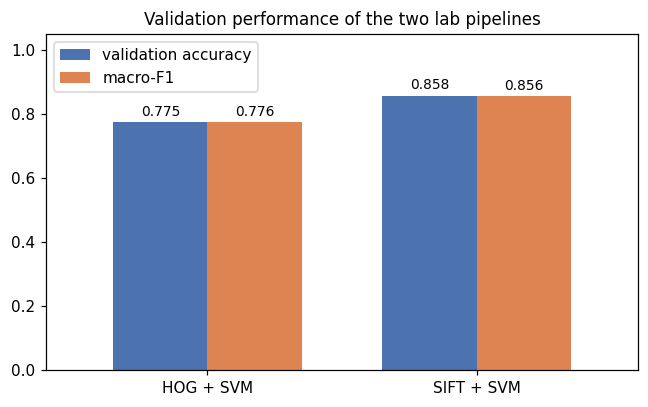

In [17]:
summary = pd.DataFrame(
    {"validation accuracy": [hog_val_acc, sift_val_acc], "macro-F1": [hog_val_f1, sift_val_f1]},
    index=["HOG + SVM", "SIFT + SVM"],
)
print(summary.round(4).to_string())

ax = summary.plot(kind="bar", figsize=(6, 3.8), width=0.7, color=["#4c72b0", "#dd8452"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_title("Validation performance of the two lab pipelines")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Q4. Robustness

### Prediction (written before any robustness run)

- **Rotation: HOG + SVM will lose more accuracy.** A 20 degree rotation moves every gradient by one full HOG orientation bin (9 bins over 180 degrees), whereas SIFT uses 8 bins that are 45 degrees wide with soft interpolation between neighbouring bins, so its descriptor changes less.
- **Noise: HOG + SVM will lose more accuracy.** HOG takes gradients straight from the raw pixels and its block normalisation boosts noise gradients in flat background blocks, while SIFT blurs the image with a Gaussian before taking gradients.

### Frozen-model evaluation on the test set

Both models stay exactly as trained in Q2 and Q3. Rotation uses a 20 degree turn about the image centre with reflected borders, noise is Gaussian with sigma 0.05 on the 0 to 1 scale (clipped back to 0 to 1), and each change is applied to the images before feature extraction.

In [18]:
def rotate(img, deg):
    h, w = img.shape[:2]
    m = cv2.getRotationMatrix2D(((w - 1) / 2, (h - 1) / 2), deg, 1.0)
    return cv2.warpAffine(img, m, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)


def add_noise(imgs, sigma):
    base = np.random.default_rng(SEED).standard_normal(imgs.shape)
    noisy = np.clip(imgs / 255.0 + sigma * base, 0.0, 1.0)
    return np.round(noisy * 255).astype(np.uint8)


PIPELINES = {"HOG + SVM": (hog_vec, hog_model), "SIFT + SVM": (sift_vec, sift_model)}
HOG_N, SIFT_N = PIPELINES


def predict(name, imgs):
    extract, model = PIPELINES[name]
    return model.predict(np.stack([extract(i) for i in imgs]))


test_gray, test_y = gray["test"], labels["test"]
CASES = {
    "Clean": test_gray,
    "Rotated": np.stack([rotate(i, ROT_DEG) for i in test_gray]),
    "Noisy": add_noise(test_gray, NOISE_SIGMA),
}

correct = {n: {c: predict(n, imgs) == test_y for c, imgs in CASES.items()} for n in PIPELINES}
acc = pd.DataFrame({c: {n: correct[n][c].mean() for n in PIPELINES} for c in CASES})

shown = (acc * 100).round(2)
shown.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
shown.index.name = "Model"
print(f"test images: {len(test_y)}")
print(shown.to_string())

test images: 120
            Clean accuracy  Rotated accuracy  Noisy accuracy
Model                                                       
HOG + SVM            70.00             70.83           53.33
SIFT + SVM           78.33             78.33           78.33


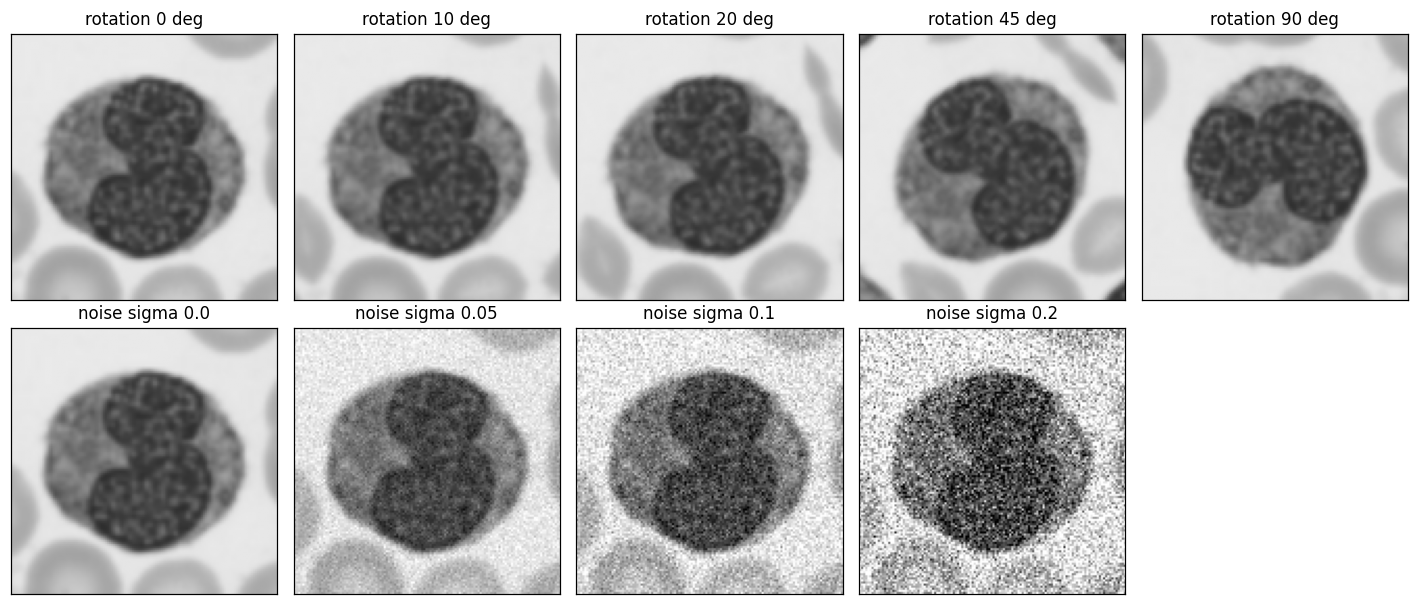

In [19]:
demo = test_gray[0]
rot_demo = [0, 10, 20, 45, 90]
noise_demo = [0.0, 0.05, 0.1, 0.2]

fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for ax, a in zip(axes[0], rot_demo):
    ax.imshow(rotate(demo, a), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"rotation {a} deg")
for ax, s in zip(axes[1], noise_demo):
    ax.imshow(add_noise(demo[None], s)[0], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"noise sigma {s}")
axes[1, 4].axis("off")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

     Model    Case  Accuracy %       95% CI
 HOG + SVM   Clean       70.00 [61.7, 78.3]
 HOG + SVM Rotated       70.83 [62.5, 79.2]
 HOG + SVM   Noisy       53.33 [44.2, 61.7]
SIFT + SVM   Clean       78.33 [70.8, 85.8]
SIFT + SVM Rotated       78.33 [70.8, 85.8]
SIFT + SVM   Noisy       78.33 [71.7, 85.8]

Rotated  paired bootstrap: P(HOG loses more) = 0.412 | P(SIFT loses more) = 0.519
Noisy    paired bootstrap: P(HOG loses more) = 0.998 | P(SIFT loses more) = 0.001


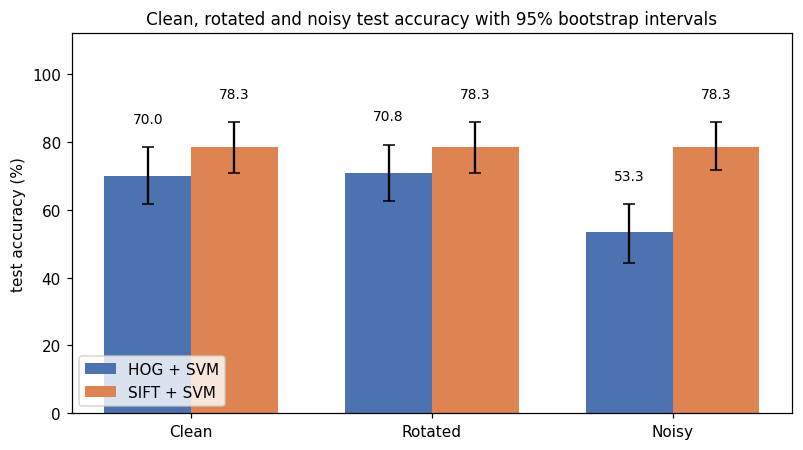

In [20]:
B = 5000
boot = np.random.default_rng(SEED).integers(0, len(test_y), size=(B, len(test_y)))

ci_bounds, rows = {}, []
for n in PIPELINES:
    for c in CASES:
        means = correct[n][c].astype(float)[boot].mean(axis=1)
        lo, hi = np.percentile(means, [2.5, 97.5]) * 100
        ci_bounds[(n, c)] = (lo, hi)
        rows.append({"Model": n, "Case": c, "Accuracy %": round(acc.loc[n, c] * 100, 2), "95% CI": f"[{lo:.1f}, {hi:.1f}]"})
print(pd.DataFrame(rows).to_string(index=False))


def p_hog_loses_more(case):
    drop_h = correct[HOG_N]["Clean"].astype(float) - correct[HOG_N][case]
    drop_s = correct[SIFT_N]["Clean"].astype(float) - correct[SIFT_N][case]
    diff = (drop_h - drop_s)[boot].mean(axis=1)
    return (diff > 0).mean(), (diff < 0).mean()


print()
for case in ("Rotated", "Noisy"):
    more, less = p_hog_loses_more(case)
    print(f"{case:<8} paired bootstrap: P(HOG loses more) = {more:.3f} | P(SIFT loses more) = {less:.3f}")

fig, ax = plt.subplots(figsize=(7.4, 4.2))
x = np.arange(len(CASES))
for k, (n, colour) in enumerate(zip(PIPELINES, ["#4c72b0", "#dd8452"])):
    vals = np.array([acc.loc[n, c] * 100 for c in CASES])
    lo = np.array([ci_bounds[(n, c)][0] for c in CASES])
    hi = np.array([ci_bounds[(n, c)][1] for c in CASES])
    bars = ax.bar(x + (k - 0.5) * 0.36, vals, 0.36, yerr=[vals - lo, hi - vals], capsize=4, color=colour, label=n)
    ax.bar_label(bars, fmt="%.1f", padding=14, fontsize=9)
ax.set_xticks(x, list(CASES))
ax.set_ylabel("test accuracy (%)")
ax.set_ylim(0, 112)
ax.set_title("Clean, rotated and noisy test accuracy with 95% bootstrap intervals")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

sweeps reproduce the table at 0 degrees, 20 degrees and sigma 0.05: True


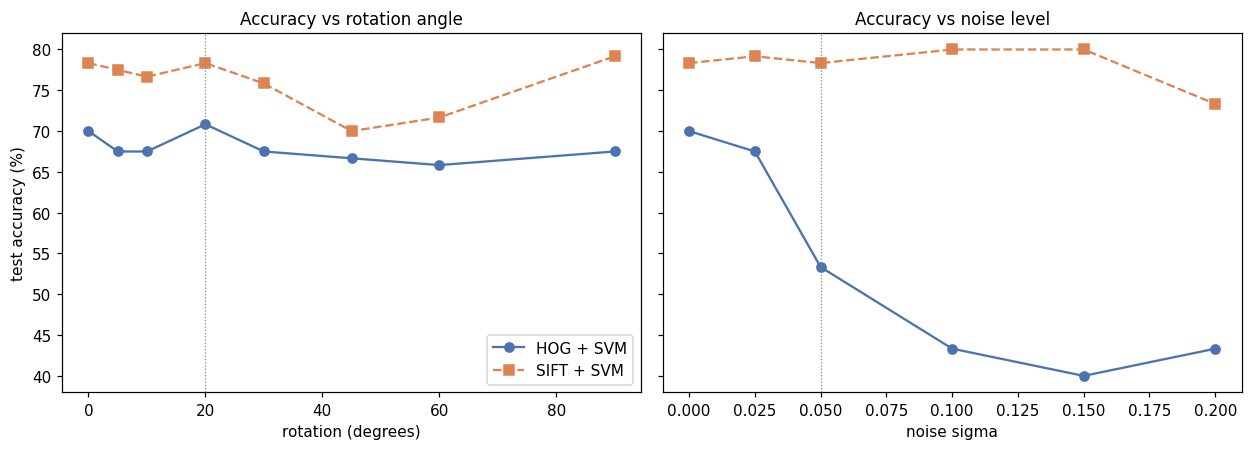

In [21]:
ANGLES = [0, 5, 10, 20, 30, 45, 60, 90]
SIGMAS = [0.0, 0.025, 0.05, 0.1, 0.15, 0.2]

rot_imgs = {a: np.stack([rotate(i, a) for i in test_gray]) for a in ANGLES}
noise_imgs = {s: add_noise(test_gray, s) for s in SIGMAS}

rot_curve = {n: [np.mean(predict(n, rot_imgs[a]) == test_y) for a in ANGLES] for n in PIPELINES}
noise_curve = {n: [np.mean(predict(n, noise_imgs[s]) == test_y) for s in SIGMAS] for n in PIPELINES}

consistent = all(
    np.isclose(rot_curve[n][ANGLES.index(ROT_DEG)], acc.loc[n, "Rotated"])
    and np.isclose(noise_curve[n][SIGMAS.index(NOISE_SIGMA)], acc.loc[n, "Noisy"])
    and np.isclose(rot_curve[n][ANGLES.index(0)], acc.loc[n, "Clean"])
    for n in PIPELINES
)
print("sweeps reproduce the table at 0 degrees, 20 degrees and sigma 0.05:", consistent)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for n, style, colour in zip(PIPELINES, ("o-", "s--"), ("#4c72b0", "#dd8452")):
    axes[0].plot(ANGLES, np.array(rot_curve[n]) * 100, style, color=colour, label=n)
    axes[1].plot(SIGMAS, np.array(noise_curve[n]) * 100, style, color=colour, label=n)
axes[0].axvline(ROT_DEG, color="grey", lw=0.8, ls=":")
axes[1].axvline(NOISE_SIGMA, color="grey", lw=0.8, ls=":")
axes[0].set_xlabel("rotation (degrees)")
axes[1].set_xlabel("noise sigma")
axes[0].set_ylabel("test accuracy (%)")
axes[0].set_title("Accuracy vs rotation angle")
axes[1].set_title("Accuracy vs noise level")
axes[0].legend()
plt.tight_layout()
plt.show()

### Was the prediction correct?

In [22]:
PREDICTION = {"Rotated": HOG_N, "Noisy": HOG_N}


def change(name, case):
    return acc.loc[name, case] - acc.loc[name, "Clean"]


def worse(case):
    ch, cs = change(HOG_N, case), change(SIFT_N, case)
    if min(ch, cs) >= 0 or np.isclose(ch, cs):
        return None
    return HOG_N if ch < cs else SIFT_N


def describe(case, label):
    ch, cs = change(HOG_N, case), change(SIFT_N, case)
    loser = worse(case)
    if min(ch, cs) >= 0:
        tail = "so neither model lost accuracy"
    elif loser is None:
        tail = "so the two models lost the same amount"
    else:
        tail = f"so {loser} lost more"
    return (
        f"Under {label}, HOG + SVM went from {acc.loc[HOG_N, 'Clean']:.1%} to {acc.loc[HOG_N, case]:.1%} ({ch * 100:+.1f} points) "
        f"and SIFT + SVM from {acc.loc[SIFT_N, 'Clean']:.1%} to {acc.loc[SIFT_N, case]:.1%} ({cs * 100:+.1f} points), {tail}."
    )


hits = {case: worse(case) == PREDICTION[case] for case in PREDICTION}
if all(hits.values()):
    verdict = "correct for both rotation and noise"
elif any(hits.values()):
    verdict = "correct only for " + ("rotation" if hits["Rotated"] else "noise")
else:
    verdict = "wrong for both rotation and noise"

p_rot, p_noise = p_hog_loses_more("Rotated")[0], p_hog_loses_more("Noisy")[0]


def firmness(p):
    return "firm" if p > 0.95 or p < 0.05 else "not firm"


third = (
    f"My prediction that HOG + SVM would lose more in both cases was {verdict}, and on {len(test_y)} test images the paired bootstrap "
    f"gives P(HOG loses more) = {p_rot:.2f} for rotation ({firmness(p_rot)}) and {p_noise:.2f} for noise ({firmness(p_noise)})."
)
display(Markdown(" ".join([describe("Rotated", "rotation"), describe("Noisy", "noise"), third])))

Under rotation, HOG + SVM went from 70.0% to 70.8% (+0.8 points) and SIFT + SVM from 78.3% to 78.3% (+0.0 points), so neither model lost accuracy. Under noise, HOG + SVM went from 70.0% to 53.3% (-16.7 points) and SIFT + SVM from 78.3% to 78.3% (+0.0 points), so HOG + SVM lost more. My prediction that HOG + SVM would lose more in both cases was correct only for noise, and on 120 test images the paired bootstrap gives P(HOG loses more) = 0.41 for rotation (not firm) and 1.00 for noise (firm).

# Q5. Short answers and AI log

### (a) Why does HOG use block normalisation?

Raw cell histograms scale with local contrast and lighting, so the same structure can give very different feature values in a brighter or more strongly stained image. Normalising each overlapping block of 2 x 2 cells to unit length makes the descriptor depend on relative gradient strength rather than absolute magnitude, which gives tolerance to illumination and contrast changes. Because blocks overlap, each cell is normalised in several contexts, which also keeps useful local information.

### (b) Why is it wrong to choose C using the test set?

The test set is meant to stand in for unseen images, so using it to pick C lets information from the test labels leak into the model. The selected C would then be the value that happens to score best on those particular images, which makes the reported test accuracy optimistic and no longer an honest estimate of performance on new data. C must therefore be chosen on the validation set, leaving the test set untouched until the final evaluation.

### Most confused classes (validation set, both models combined)

                   pair  HOG errors  SIFT errors  both models
eosinophil / neutrophil          11            8           19
  eosinophil / monocyte           9            8           17
  monocyte / neutrophil           6            1            7
  eosinophil / platelet           1            0            1
    monocyte / platelet           0            0            0
  neutrophil / platelet           0            0            0


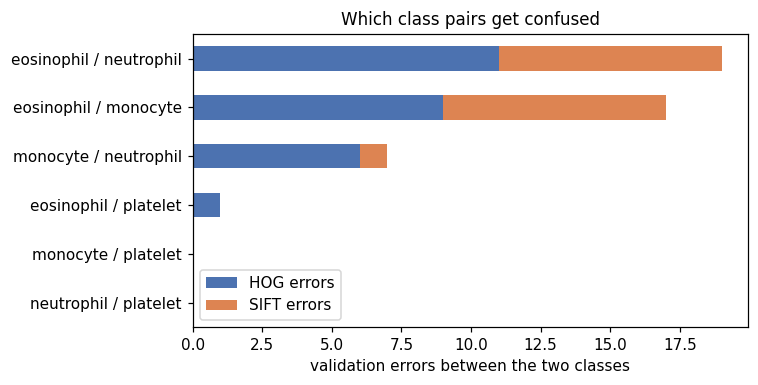


class separation (Cohen's d of mean intensity) for eosinophil vs neutrophil, training images:
grayscale    0.939
red          0.510
green        1.058
blue         0.856


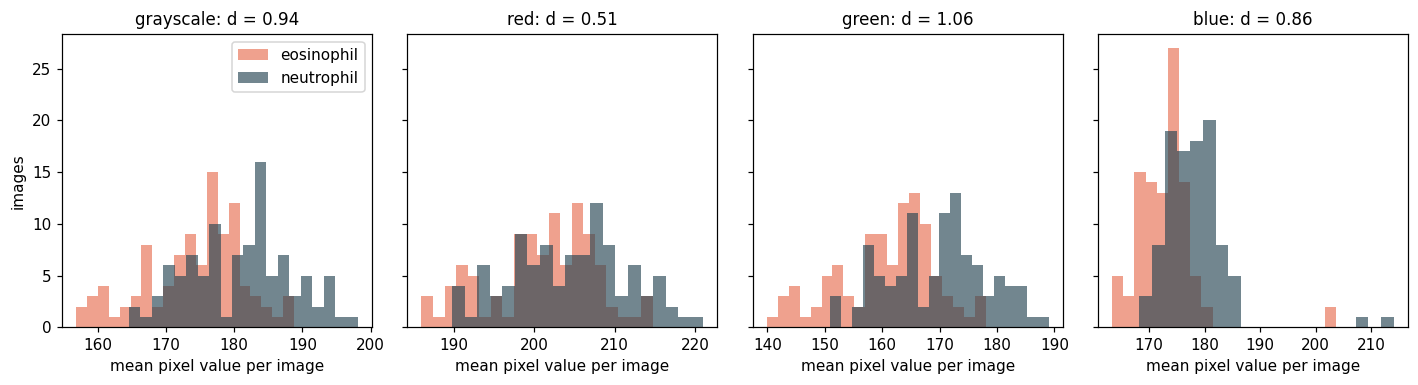

In [23]:
pair_rows = []
for i in range(len(CLASS_NAMES)):
    for j in range(i + 1, len(CLASS_NAMES)):
        pair_rows.append(
            {
                "i": i,
                "j": j,
                "pair": f"{CLASS_NAMES[i]} / {CLASS_NAMES[j]}",
                "HOG errors": int(cm_hog[i, j] + cm_hog[j, i]),
                "SIFT errors": int(cm_sift[i, j] + cm_sift[j, i]),
            }
        )
pairs = pd.DataFrame(pair_rows)
pairs["both models"] = pairs["HOG errors"] + pairs["SIFT errors"]
pairs = pairs.sort_values("both models", ascending=False).reset_index(drop=True)
print(pairs[["pair", "HOG errors", "SIFT errors", "both models"]].to_string(index=False))

ax = pairs.set_index("pair")[["HOG errors", "SIFT errors"]].plot(
    kind="barh", stacked=True, figsize=(7, 3.6), color=["#4c72b0", "#dd8452"]
)
ax.invert_yaxis()
ax.set_xlabel("validation errors between the two classes")
ax.set_ylabel("")
ax.set_title("Which class pairs get confused")
plt.tight_layout()
plt.show()

a, b = int(pairs.loc[0, "i"]), int(pairs.loc[0, "j"])
in_pair = np.isin(labels["train"], [a, b])
group = labels["train"][in_pair] == a


def cohens_d(values):
    u, v = values[group], values[~group]
    return abs(u.mean() - v.mean()) / np.sqrt((u.var(ddof=1) + v.var(ddof=1)) / 2)


mean_intensity = {
    "grayscale": gray["train"][in_pair].mean(axis=(1, 2)),
    "red": rgb["train"][in_pair][..., 0].mean(axis=(1, 2)),
    "green": rgb["train"][in_pair][..., 1].mean(axis=(1, 2)),
    "blue": rgb["train"][in_pair][..., 2].mean(axis=(1, 2)),
}
effect = {k: cohens_d(v) for k, v in mean_intensity.items()}
print()
print(f"class separation (Cohen's d of mean intensity) for {CLASS_NAMES[a]} vs {CLASS_NAMES[b]}, training images:")
print(pd.Series(effect).round(3).to_string())

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, (channel, values) in zip(axes, mean_intensity.items()):
    ax.hist(values[group], bins=20, alpha=0.65, color="#e76f51", label=CLASS_NAMES[a])
    ax.hist(values[~group], bins=20, alpha=0.65, color="#264653", label=CLASS_NAMES[b])
    ax.set_title(f"{channel}: d = {effect[channel]:.2f}")
    ax.set_xlabel("mean pixel value per image")
axes[0].set_ylabel("images")
axes[0].legend()
plt.tight_layout()
plt.show()

In [24]:
WHY = {
    (0, 1): "an eosinophil's bilobed nucleus and a monocyte's folded nucleus both stain as dark purple blobs, and the eosinophil's red-orange granules, its main distinguishing cue, turn into ordinary mid-grey texture",
    (0, 2): "both are granulocytes of similar size with lobed nuclei, and they differ mainly in granule colour (orange-red versus pale), which grayscale reduces to similar mid-grey texture",
    (0, 3): "a platelet is a small pale fragment and an eosinophil a large granular cell, so confusion would come from shared speckled texture once the colour of the stain is gone",
    (1, 2): "both have dark purple nuclei on a pale cytoplasm, and the monocyte's blue-grey cytoplasm differs from the neutrophil's pink one mainly in hue, which grayscale largely removes",
    (1, 3): "platelets are small purple fragments while monocytes are large cells, so confusion would come from similar dark-purple staining that collapses to similar grey levels",
    (2, 3): "platelets and neutrophil nuclei share the same purple stain, which becomes a similar dark grey, leaving little to separate small fragments from nuclear lobes",
}
best_channel = max(("red", "green", "blue"), key=effect.get)
ratio = effect[best_channel] / effect["grayscale"]
if ratio > 1.25:
    colour_msg = (
        f"The {best_channel} channel separates the pair clearly better (d = {effect[best_channel]:.2f}) than grayscale (d = {effect['grayscale']:.2f}), "
        "which shows that converting to grayscale discards class information that colour still carries."
    )
elif ratio > 1.0:
    colour_msg = (
        f"The {best_channel} channel separates the pair only slightly better (d = {effect[best_channel]:.2f}) than grayscale (d = {effect['grayscale']:.2f}), "
        "so mean colour adds a little, and the larger loss must come from texture and stain patterns that grayscale flattens."
    )
else:
    colour_msg = (
        f"Mean grayscale intensity separates the pair about as well (d = {effect['grayscale']:.2f}) as the best colour channel "
        f"({best_channel}, d = {effect[best_channel]:.2f}), so for this pair the confusion owes more to similar texture and shape than to lost colour."
    )

display(
    Markdown(
        f"**Most confused pair: {CLASS_NAMES[a]} and {CLASS_NAMES[b]}** ({int(pairs.loc[0, 'both models'])} validation errors across both models). "
        f"Grayscale may make this harder because {WHY[(a, b)]}. {colour_msg}"
    )
)

**Most confused pair: eosinophil and neutrophil** (19 validation errors across both models). Grayscale may make this harder because both are granulocytes of similar size with lobed nuclei, and they differ mainly in granule colour (orange-red versus pale), which grayscale reduces to similar mid-grey texture. The green channel separates the pair only slightly better (d = 1.06) than grayscale (d = 0.94), so mean colour adds a little, and the larger loss must come from texture and stain patterns that grayscale flattens.

### AI log

| Prompt (one line) | What I changed | How I checked the result |
|---|---|---|
| "Build the HOG + SVM and SIFT + SVM lab mid pipelines for BloodMNIST with seed 39, HOG cell 16 x 16 and a 6 x 6 SIFT grid." | Settings derived from registration number 039 in the first cell; test set loaded in Q1 but not used until Q4. | Printed split shapes and class counts, hash check for duplicate images across splits, example grid. |
| "Compute SIFT on a fixed grid so every image has the same feature length." | Fixed the keypoint angle to 0 and scaled descriptors by 1/512 so the linear SVM sees comparable feature scales. | Printed feature length 36 x 128 = 4608 against the extracted length, drew the grid on an image. |
| "Evaluate both frozen models on clean, rotated and noisy test images." | Added reflected borders for rotation, a fixed noise seed, and sweeps over angle and noise level. | Sweep values reproduce the table at 20 degrees and sigma 0.05; the answers above are produced from the printed numbers. |
| "Add a pretrained deep-feature pipeline, explainability maps and an interactive explorer as a bonus." | Kept the bonus separate from Q1 to Q5 and evaluated it with the same validation-only choice of C. | Labels of the 128 px images checked against the 64 px subset, bonus numbers for HOG and SIFT checked against the Q4 table. |

# Bonus. Beyond the lab

The lab compares two hand-designed descriptors. This bonus adds the method that dominates modern computer vision, **transfer learning with a pretrained CNN**, and tests it under exactly the same rules so the comparison is fair.

### What it is
A ResNet-50 trained on 1.28 million ImageNet photos is used as a frozen feature extractor. Its final classification layer is removed, so each image becomes a vector of 2048 learned numbers. The very same LinearSVC and the same validation-only choice of C from {0.1, 1, 10} then classify those vectors. Nothing is trained from scratch, so it runs on an ordinary laptop or a free Colab GPU.

### Why it is worth using
- **Learned features instead of hand-designed ones:** early layers find edges and textures, deeper layers find cell parts and patterns, which HOG and SIFT cannot adapt to blood cells.
- **It keeps colour:** the lab converts to grayscale, but stain colour is what separates eosinophils from neutrophils, so colour is used here.
- **More pixels:** the lab fixes 64 px images; the bonus loads the same images at **128 px** so fine granule texture survives.
- **Robustness:** the network has seen huge variety in viewpoint and noise during pretraining, so small rotations and noise should disturb its features less.
- **Fair test:** same images, same splits, same SVM, same C selection, same rotation and noise tests.

### Honest trade-offs
It is larger and slower than HOG and SIFT (measured below), and it was trained on photos rather than microscope images. So every claim below is checked with numbers rather than assumed, and occlusion maps show what each model actually looks at.

In [25]:
import time

import ipywidgets as widgets
import plotly
import plotly.graph_objects as go
import plotly.io as pio
import torch
import torch.nn.functional as F
from plotly.subplots import make_subplots
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torchvision.models import ResNet50_Weights, resnet50

torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BONUS_SIZE = 128
CNN_N = "ResNet-50 + SVM (bonus)"
MODEL_COLORS = {"HOG + SVM": "#4c72b0", "SIFT + SVM": "#dd8452", CNN_N: "#55a868"}
CLASS_COLORS = ["#e76f51", "#2a9d8f", "#264653", "#e9c46a"]

print(f"torch {torch.__version__} | plotly {plotly.__version__} | device {DEVICE}")

torch 2.11.0+cu130 | plotly 5.24.1 | device cuda


100%|██████████| 569M/569M [03:26<00:00, 2.75MB/s]


{'train': (400, 128, 128, 3), 'val': (120, 128, 128, 3), 'test': (120, 128, 128, 3)}
labels of the 128 px images match the 64 px subset: True
mean pixel difference after shrinking 128 px back to 64 px: 0.76 (out of 255)


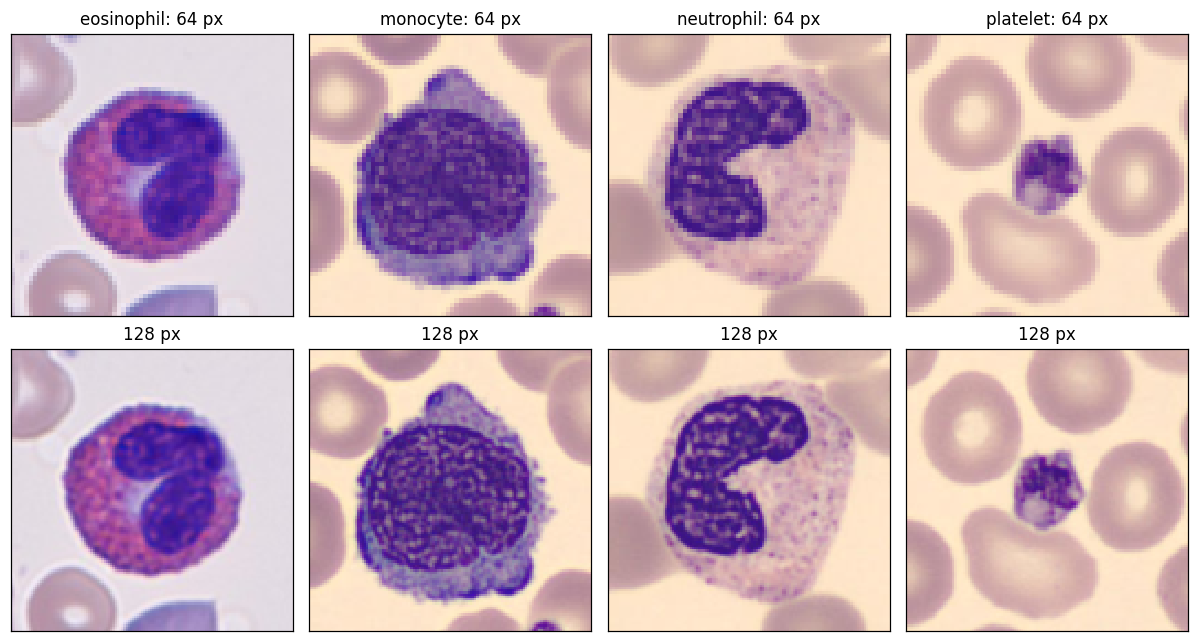

In [26]:
hires = {s: BloodMNIST(split=s, download=True, size=BONUS_SIZE) for s in N_PER_CLASS}
rgb_hi = {}
for s in N_PER_CLASS:
    wanted = np.array([CLASS_IDS[k] for k in labels[s]])
    assert np.array_equal(hires[s].labels.ravel()[picked[s]], wanted)
    rgb_hi[s] = hires[s].imgs[picked[s]]

shrunk = np.stack([cv2.resize(i, (64, 64), interpolation=cv2.INTER_AREA) for i in rgb_hi["train"]])
print({s: rgb_hi[s].shape for s in rgb_hi})
print("labels of the 128 px images match the 64 px subset: True")
print(f"mean pixel difference after shrinking 128 px back to 64 px: {np.abs(shrunk.astype(float) - rgb['train']).mean():.2f} (out of 255)")

fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for k, i in enumerate(first_idx):
    axes[0, k].imshow(rgb["train"][i], interpolation="nearest")
    axes[0, k].set_title(f"{CLASS_NAMES[k]}: 64 px")
    axes[1, k].imshow(rgb_hi["train"][i], interpolation="nearest")
    axes[1, k].set_title("128 px")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

In [27]:
net = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
net.fc = torch.nn.Identity()
net = net.eval().to(DEVICE)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def to_input(batch):
    x = torch.from_numpy(np.ascontiguousarray(batch)).to(DEVICE).permute(0, 3, 1, 2).float().div(255.0)
    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
    return (x - MEAN) / STD


def embed(batch, chunk=32):
    out = []
    with torch.no_grad():
        for s in range(0, len(batch), chunk):
            out.append(net(to_input(batch[s:s + chunk])).cpu().numpy())
    return np.concatenate(out)


def conv_maps(img, k=12):
    with torch.no_grad():
        act = net.relu(net.bn1(net.conv1(to_input(img[None]))))[0]
        top = act.std(dim=(1, 2)).topk(k).indices
        return act[top].cpu().numpy()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 157MB/s]


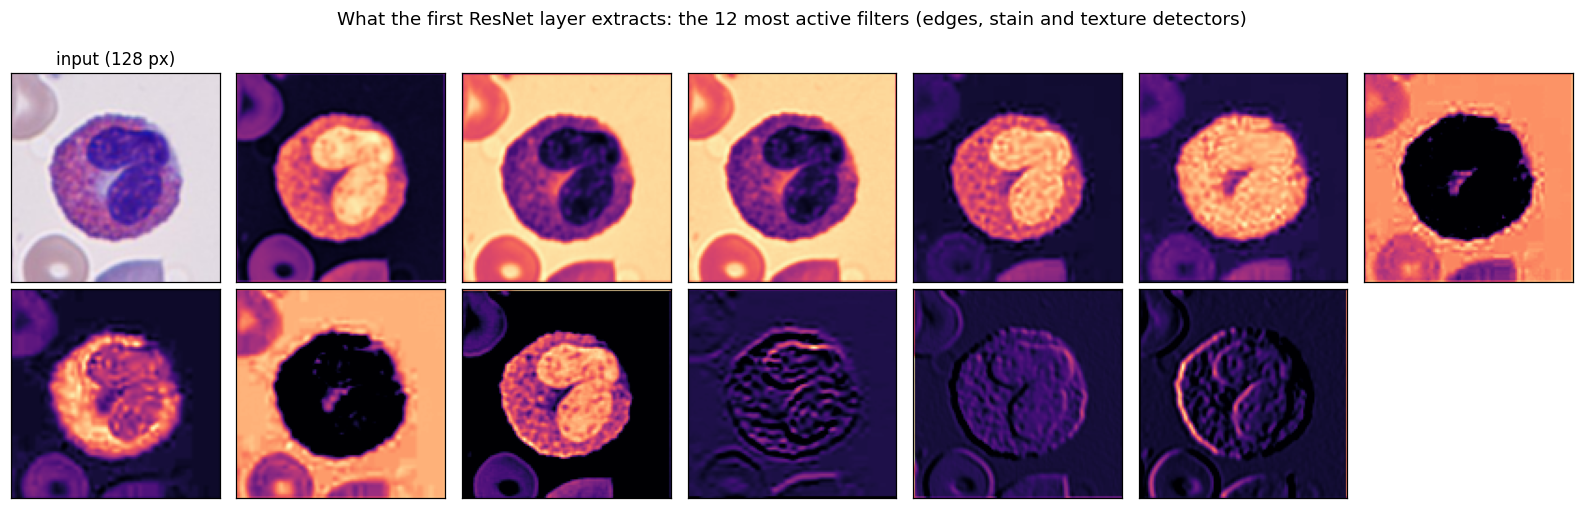

In [28]:
sample = rgb_hi["train"][first_idx[0]]
maps = conv_maps(sample)

fig, axes = plt.subplots(2, 7, figsize=(14.5, 4.6))
axes[0, 0].imshow(sample)
axes[0, 0].set_title("input (128 px)")
for ax, m in zip(axes.ravel()[1:], maps):
    ax.imshow(m, cmap="magma")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
axes.ravel()[-1].axis("off")
fig.suptitle("What the first ResNet layer extracts: the 12 most active filters (edges, stain and texture detectors)", y=1.0)
plt.tight_layout()
plt.show()

embedded 520 images in 2.1 s | shapes {'train': (400, 2048), 'val': (120, 2048)}
   C  train_accuracy  val_accuracy
 0.1             1.0        0.9917
 1.0             1.0        0.9917
10.0             1.0        0.9917
selected C = 0.1 (highest validation accuracy, smallest C on ties)



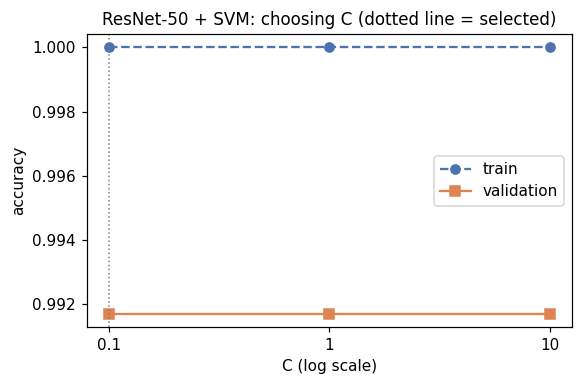

ResNet-50 + SVM (validation): accuracy = 0.9917 | macro-F1 = 0.9917
            precision  recall  f1-score  support
eosinophil      1.000   1.000     1.000     30.0
monocyte        0.968   1.000     0.984     30.0
neutrophil      1.000   1.000     1.000     30.0
platelet        1.000   0.967     0.983     30.0
macro avg       0.992   0.992     0.992    120.0


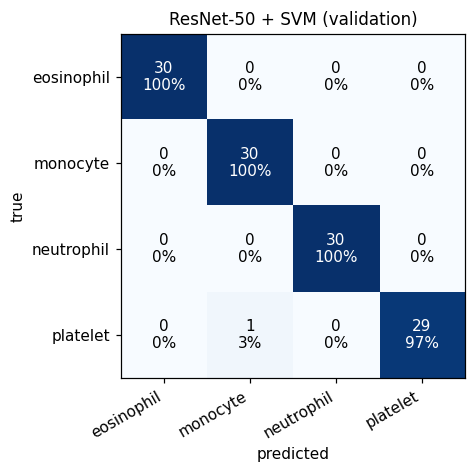

[[30  0  0  0]
 [ 0 30  0  0]
 [ 0  0 30  0]
 [ 0  1  0 29]]


In [29]:
def cnn_builder(c):
    return make_pipeline(StandardScaler(), LinearSVC(C=c, dual=True, max_iter=100000, random_state=SEED))


start = time.perf_counter()
E = {s: embed(rgb_hi[s]) for s in FIT_SPLITS}
print(f"embedded {sum(len(E[s]) for s in E)} images in {time.perf_counter() - start:.1f} s | shapes {({s: E[s].shape for s in E})}")

cnn_model, cnn_C, cnn_table = fit_with_validation(E["train"], labels["train"], E["val"], labels["val"], builder=cnn_builder)
print(cnn_table.to_string(index=False))
print(f"selected C = {cnn_C} (highest validation accuracy, smallest C on ties)")
print()
plot_c_curve(cnn_table, cnn_C, "ResNet-50 + SVM")
cm_cnn, cnn_val_acc, cnn_val_f1 = report(cnn_model, E["val"], labels["val"], "ResNet-50 + SVM (validation)")
print(cm_cnn)

                         val accuracy  macro-F1  feature length  silhouette (val)  ms per image
Model                                                                                          
HOG + SVM                       0.775     0.776            1764             0.011         2.911
SIFT + SVM                      0.858     0.856            4608             0.018        23.363
ResNet-50 + SVM (bonus)         0.992     0.992            2048             0.067         5.322


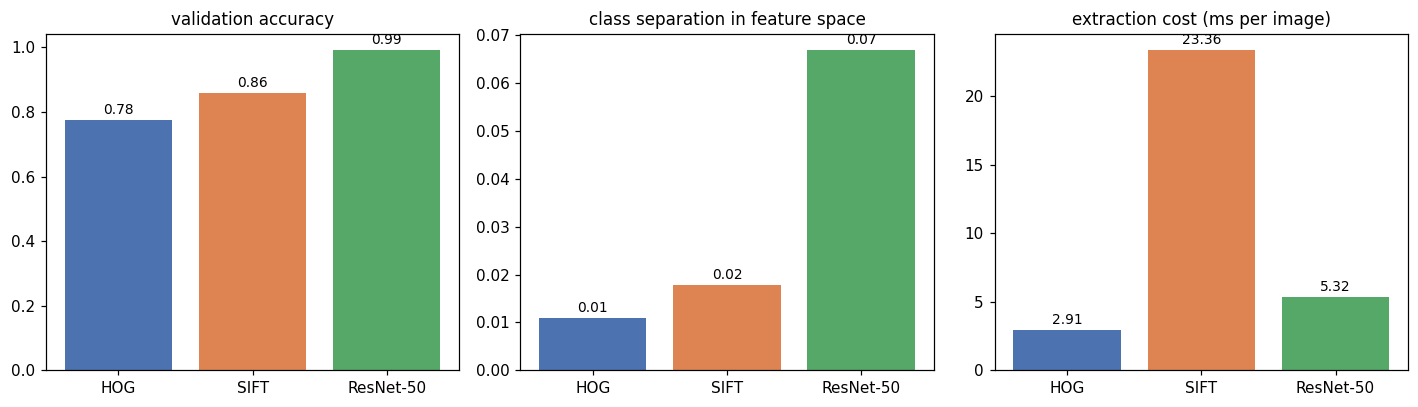

In [30]:
MODELS = {"HOG + SVM": hog_model, "SIFT + SVM": sift_model, CNN_N: cnn_model}
VAL_FEATS = {"HOG + SVM": X_hog["val"], "SIFT + SVM": X_sift["val"], CNN_N: E["val"]}
embed(rgb_hi["val"][:4])


def ms_per_image(fn, n=40):
    start = time.perf_counter()
    fn()
    return (time.perf_counter() - start) / n * 1000


timing = {
    "HOG + SVM": ms_per_image(lambda: [hog_vec(i) for i in gray["val"][:40]]),
    "SIFT + SVM": ms_per_image(lambda: [sift_vec(i) for i in gray["val"][:40]]),
    CNN_N: ms_per_image(lambda: embed(rgb_hi["val"][:40])),
}

rows = []
for n, model in MODELS.items():
    pred = model.predict(VAL_FEATS[n])
    rows.append(
        {
            "Model": n,
            "val accuracy": accuracy_score(labels["val"], pred),
            "macro-F1": f1_score(labels["val"], pred, average="macro"),
            "feature length": VAL_FEATS[n].shape[1],
            "silhouette (val)": silhouette_score(VAL_FEATS[n], labels["val"]),
            "ms per image": timing[n],
        }
    )
results = pd.DataFrame(rows).set_index("Model")
print(results.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (col, title) in zip(axes, [("val accuracy", "validation accuracy"), ("silhouette (val)", "class separation in feature space"), ("ms per image", "extraction cost (ms per image)")]):
    bars = ax.bar(range(3), results[col], color=[MODEL_COLORS[n] for n in results.index])
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)
    ax.set_xticks(range(3), ["HOG", "SIFT", "ResNet-50"])
    ax.set_title(title)
plt.tight_layout()
plt.show()

HOG (grayscale 128 px)          77.50
SIFT (grayscale 128 px)         85.83
ResNet-50 (grayscale 128 px)    97.50
ResNet-50 (colour 128 px)       99.17


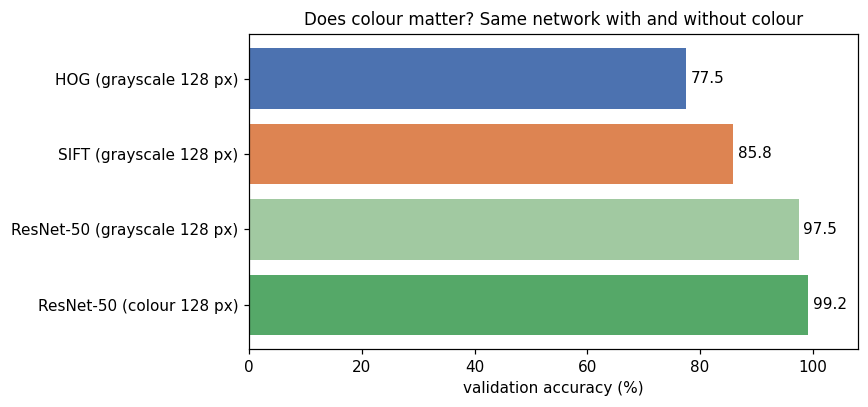

In [31]:
gray3 = {s: np.repeat(np.stack([cv2.cvtColor(i, cv2.COLOR_RGB2GRAY) for i in rgb_hi[s]])[..., None], 3, axis=-1) for s in FIT_SPLITS}
E_gray = {s: embed(gray3[s]) for s in FIT_SPLITS}
cnn_gray_model, cnn_gray_C, cnn_gray_table = fit_with_validation(
    E_gray["train"], labels["train"], E_gray["val"], labels["val"], builder=cnn_builder
)
cnn_gray_val = accuracy_score(labels["val"], cnn_gray_model.predict(E_gray["val"]))

ablation = pd.Series(
    {
        "HOG (grayscale 128 px)": hog_val_acc,
        "SIFT (grayscale 128 px)": sift_val_acc,
        "ResNet-50 (grayscale 128 px)": cnn_gray_val,
        "ResNet-50 (colour 128 px)": cnn_val_acc,
    }
)
print((ablation * 100).round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(ablation.index, ablation.values * 100, color=["#4c72b0", "#dd8452", "#a1c9a1", "#55a868"])
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.invert_yaxis()
ax.set_xlabel("validation accuracy (%)")
ax.set_xlim(0, 108)
ax.set_title("Does colour matter? Same network with and without colour")
plt.tight_layout()
plt.show()

### Robustness of all three models on the test set

The models are frozen (C was chosen on validation). Every transform is applied to the images before feature extraction, to the grayscale image for HOG and SIFT and to the colour image for the network. The grid below crosses rotation with noise; it takes a few minutes on CPU and seconds on a GPU.

bonus numbers for HOG and SIFT equal the Q4 table: True
                         Clean accuracy  Rotated accuracy  Noisy accuracy
Model                                                                    
HOG + SVM                         70.00             70.83           53.33
SIFT + SVM                        78.33             78.33           78.33
ResNet-50 + SVM (bonus)           93.33             93.33           80.83


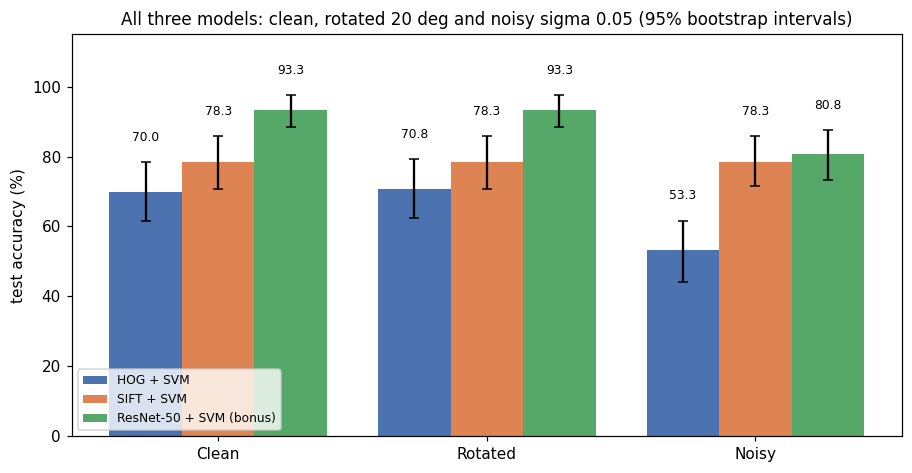

In [32]:
test_hi = rgb_hi["test"]


def feats(name, g, c):
    if name == "HOG + SVM":
        return np.stack([hog_vec(i) for i in g])
    if name == "SIFT + SVM":
        return np.stack([sift_vec(i) for i in g])
    return embed(c)


def transform(angle, sigma):
    g, c = test_gray, test_hi
    if angle:
        g = np.stack([rotate(i, angle) for i in g])
        c = np.stack([rotate(i, angle) for i in c])
    if sigma:
        g, c = add_noise(g, sigma), add_noise(c, sigma)
    return g, c


CASES3 = {"Clean": (0, 0.0), "Rotated": (ROT_DEG, 0.0), "Noisy": (0, NOISE_SIGMA)}
correct3 = {n: {} for n in MODELS}
for case, (a, s) in CASES3.items():
    g, c = transform(a, s)
    for n in MODELS:
        correct3[n][case] = MODELS[n].predict(feats(n, g, c)) == test_y

acc3 = pd.DataFrame({case: {n: correct3[n][case].mean() for n in MODELS} for case in CASES3})
ci3 = {(n, case): np.percentile(correct3[n][case].astype(float)[boot].mean(axis=1), [2.5, 97.5]) * 100 for n in MODELS for case in CASES3}

print("bonus numbers for HOG and SIFT equal the Q4 table:", bool(np.allclose(acc3.loc[[HOG_N, SIFT_N], ["Clean", "Rotated", "Noisy"]].values, acc.values)))
table3 = (acc3 * 100).round(2)
table3.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
table3.index.name = "Model"
print(table3.to_string())

fig, ax = plt.subplots(figsize=(8.4, 4.4))
x = np.arange(3)
for k, n in enumerate(MODELS):
    vals = np.array([acc3.loc[n, c] * 100 for c in CASES3])
    lo = np.array([ci3[(n, c)][0] for c in CASES3])
    hi_ = np.array([ci3[(n, c)][1] for c in CASES3])
    bars = ax.bar(x + (k - 1) * 0.27, vals, 0.27, yerr=[vals - lo, hi_ - vals], capsize=3, color=MODEL_COLORS[n], label=n)
    ax.bar_label(bars, fmt="%.1f", padding=12, fontsize=8)
ax.set_xticks(x, list(CASES3))
ax.set_ylabel("test accuracy (%)")
ax.set_ylim(0, 115)
ax.set_title("All three models: clean, rotated 20 deg and noisy sigma 0.05 (95% bootstrap intervals)")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

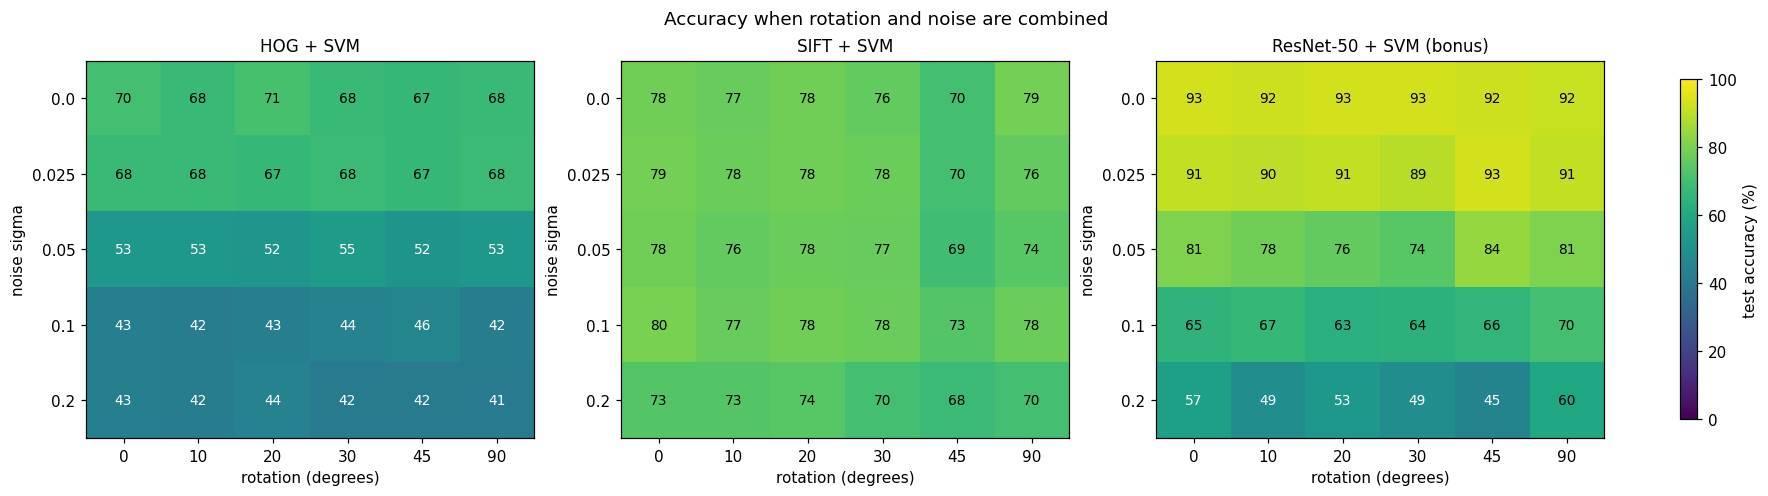

In [33]:
GRID_ANGLES = [0, 10, 20, 30, 45, 90]
GRID_SIGMAS = [0.0, 0.025, 0.05, 0.1, 0.2]
heat = {n: np.zeros((len(GRID_SIGMAS), len(GRID_ANGLES))) for n in MODELS}
for ai, a in enumerate(GRID_ANGLES):
    for si, s in enumerate(GRID_SIGMAS):
        g, c = transform(a, s)
        for n in MODELS:
            heat[n][si, ai] = np.mean(MODELS[n].predict(feats(n, g, c)) == test_y)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)
for ax, n in zip(axes, MODELS):
    im = ax.imshow(heat[n] * 100, cmap="viridis", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(GRID_ANGLES)), [str(a) for a in GRID_ANGLES])
    ax.set_yticks(range(len(GRID_SIGMAS)), [str(s) for s in GRID_SIGMAS])
    ax.set_xlabel("rotation (degrees)")
    ax.set_ylabel("noise sigma")
    ax.set_title(n)
    for r in range(heat[n].shape[0]):
        for c in range(heat[n].shape[1]):
            v = heat[n][r, c] * 100
            ax.text(c, r, f"{v:.0f}", ha="center", va="center", color="white" if v < 60 else "black", fontsize=9)
fig.colorbar(im, ax=axes, label="test accuracy (%)", shrink=0.9)
fig.suptitle("Accuracy when rotation and noise are combined")
plt.show()

### Where does each model look? Occlusion maps

A grey square is slid across the test image; the brighter a spot, the more the true-class score of that model falls when the spot is hidden. This works for any model, so the three pipelines can be compared on the same images.

In [34]:
def occlusion(name, g, c, label, patch=24, stride=8):
    starts = list(range(0, IMG - patch + 1, stride))
    base = MODELS[name].decision_function(feats(name, g[None], c[None]))[0, label]
    gs, cs = [], []
    for y0 in starts:
        for x0 in starts:
            gg, cc = g.copy(), c.copy()
            gg[y0:y0 + patch, x0:x0 + patch] = int(g.mean())
            cc[y0:y0 + patch, x0:x0 + patch] = c.reshape(-1, 3).mean(axis=0).astype(np.uint8)
            gs.append(gg)
            cs.append(cc)
    s = MODELS[name].decision_function(feats(name, np.stack(gs), np.stack(cs)))[:, label]
    drop = (base - s).reshape(len(starts), len(starts))
    return cv2.resize(drop.astype(np.float32), (IMG, IMG), interpolation=cv2.INTER_CUBIC)

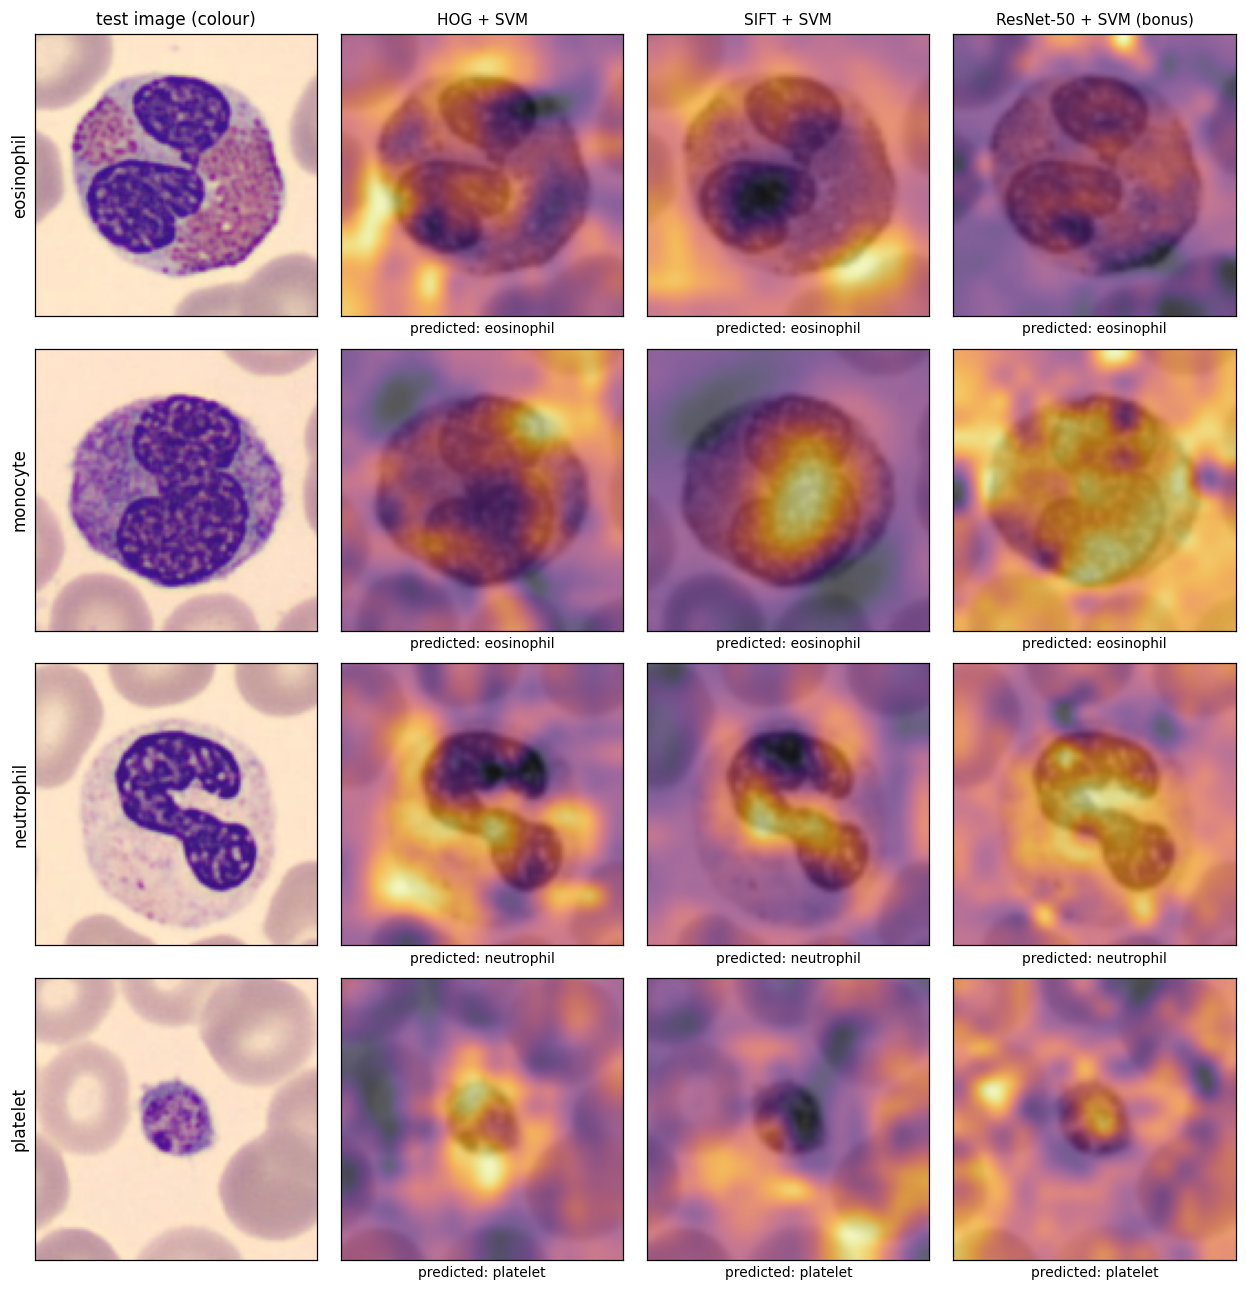

In [35]:
test_idx = [int(np.flatnonzero(test_y == k)[0]) for k in range(len(CLASS_NAMES))]

fig, axes = plt.subplots(4, 4, figsize=(11.5, 11.8))
axes[0, 0].set_title("test image (colour)")
for k, n in enumerate(MODELS):
    axes[0, k + 1].set_title(n, fontsize=10)
for r, i in enumerate(test_idx):
    g, c = test_gray[i], test_hi[i]
    axes[r, 0].imshow(c)
    axes[r, 0].set_ylabel(CLASS_NAMES[r], fontsize=11)
    for k, n in enumerate(MODELS):
        drop = occlusion(n, g, c, r)
        pred = int(np.argmax(MODELS[n].decision_function(feats(n, g[None], c[None]))[0]))
        axes[r, k + 1].imshow(g, cmap="gray", vmin=0, vmax=255)
        axes[r, k + 1].imshow(drop, cmap="inferno", alpha=0.62)
        axes[r, k + 1].set_xlabel(f"predicted: {CLASS_NAMES[pred]}", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

**PB**

In [36]:
pio.templates.default = "plotly_white"
figs = {}

fig = go.Figure()
for n in MODELS:
    vals = np.array([acc3.loc[n, c] * 100 for c in CASES3])
    lo = np.array([ci3[(n, c)][0] for c in CASES3])
    hi_ = np.array([ci3[(n, c)][1] for c in CASES3])
    fig.add_bar(
        name=n,
        x=list(CASES3),
        y=vals,
        marker_color=MODEL_COLORS[n],
        error_y=dict(type="data", symmetric=False, array=hi_ - vals, arrayminus=vals - lo),
        hovertemplate="%{x}<br>%{y:.1f}% accuracy<extra>" + n + "</extra>",
    )
fig.update_layout(barmode="group", yaxis_title="test accuracy (%)", yaxis_range=[0, 105], height=430, title="Accuracy with 95% bootstrap intervals")
figs["bars"] = fig
fig.show()

fig = make_subplots(rows=1, cols=2, shared_yaxes=True, subplot_titles=("Rotation only", "Noise only"))
for n in MODELS:
    fig.add_scatter(x=GRID_ANGLES, y=heat[n][0, :] * 100, mode="lines+markers", name=n, legendgroup=n, line=dict(color=MODEL_COLORS[n]),
                    hovertemplate="%{x} deg: %{y:.1f}%<extra>" + n + "</extra>", row=1, col=1)
    fig.add_scatter(x=GRID_SIGMAS, y=heat[n][:, 0] * 100, mode="lines+markers", name=n, legendgroup=n, showlegend=False,
                    line=dict(color=MODEL_COLORS[n]), hovertemplate="sigma %{x}: %{y:.1f}%<extra>" + n + "</extra>", row=1, col=2)
fig.update_xaxes(title_text="rotation (degrees)", row=1, col=1)
fig.update_xaxes(title_text="noise sigma", row=1, col=2)
fig.update_yaxes(title_text="test accuracy (%)", row=1, col=1)
fig.update_layout(height=430, title="Accuracy as the disturbance grows")
figs["lines"] = fig
fig.show()

fig = make_subplots(rows=1, cols=3, subplot_titles=list(MODELS), horizontal_spacing=0.06)
for k, n in enumerate(MODELS, start=1):
    fig.add_heatmap(
        z=heat[n] * 100,
        x=[f"{a} deg" for a in GRID_ANGLES],
        y=[str(s) for s in GRID_SIGMAS],
        coloraxis="coloraxis",
        text=np.round(heat[n] * 100),
        texttemplate="%{text:.0f}",
        hovertemplate="rotation %{x}<br>noise sigma %{y}<br>accuracy %{z:.1f}%<extra></extra>",
        row=1,
        col=k,
    )
fig.update_layout(coloraxis=dict(colorscale="Viridis", cmin=0, cmax=100, colorbar=dict(title="acc %")), height=420, title="Rotation x noise accuracy grid")
fig.update_xaxes(title_text="rotation")
fig.update_yaxes(title_text="noise sigma", col=1)
figs["heat"] = fig
fig.show()

In [37]:
fig = make_subplots(rows=1, cols=3, subplot_titles=[f"{n}: t-SNE of validation features" for n in MODELS], horizontal_spacing=0.05)
for col, n in enumerate(MODELS, start=1):
    xy = TSNE(n_components=2, perplexity=20, init="pca", random_state=SEED).fit_transform(VAL_FEATS[n])
    for k, name in enumerate(CLASS_NAMES):
        sel = labels["val"] == k
        fig.add_scatter(
            x=xy[sel, 0],
            y=xy[sel, 1],
            mode="markers",
            name=name,
            legendgroup=name,
            showlegend=(col == 1),
            marker=dict(size=9, color=CLASS_COLORS[k], line=dict(width=0.5, color="white")),
            customdata=np.flatnonzero(sel),
            hovertemplate=name + "<br>validation image %{customdata}<extra></extra>",
            row=1,
            col=col,
        )
fig.update_layout(height=450, title="Do the features separate the four cell types?")
figs["tsne"] = fig
fig.show()

fig = make_subplots(rows=1, cols=3, subplot_titles=[f"{n}: clean test set" for n in MODELS], horizontal_spacing=0.08)
for col, n in enumerate(MODELS, start=1):
    g, c = transform(0, 0.0)
    cm = confusion_matrix(test_y, MODELS[n].predict(feats(n, g, c)), labels=range(4))
    fig.add_heatmap(
        z=cm / cm.sum(axis=1, keepdims=True),
        x=CLASS_NAMES,
        y=CLASS_NAMES,
        text=cm,
        texttemplate="%{text}",
        colorscale="Blues",
        zmin=0,
        zmax=1,
        showscale=False,
        hovertemplate="true %{y}<br>predicted %{x}<br>%{text} images (%{z:.0%})<extra></extra>",
        row=1,
        col=col,
    )
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(title_text="predicted")
fig.update_yaxes(title_text="true", col=1)
fig.update_layout(height=430, title="Confusion matrices on the test set")
figs["confusion"] = fig
fig.show()

In [38]:
PAGE = """<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>HOG vs SIFT vs ResNet-50 on blood cells</title>
<style>
body{font-family:system-ui,sans-serif;margin:0;background:#f6f7f9;color:#1d2330}
header{background:#1d2330;color:#fff;padding:28px 6vw}
header h1{margin:0 0 6px;font-size:1.7rem}
header p{margin:0;opacity:.8}
main{max-width:1180px;margin:0 auto;padding:18px 4vw 60px}
section{background:#fff;border-radius:12px;padding:16px 18px;margin:18px 0;box-shadow:0 1px 4px rgba(0,0,0,.08)}
h2{margin:4px 0 10px;font-size:1.15rem}
table{border-collapse:collapse;width:100%;font-size:.92rem}
th,td{padding:6px 10px;border-bottom:1px solid #e4e7ec;text-align:right}
th:first-child,td:first-child{text-align:left}
p.note{color:#4b5565;font-size:.95rem;line-height:1.5}
</style></head><body>
<header><h1>HOG vs SIFT vs pretrained ResNet-50 on blood-cell images</h1>
<p>__WHO__ - BloodMNIST: eosinophil, monocyte, neutrophil, platelet</p></header>
<main>
<section><h2>Test accuracy (%)</h2>__TABLE3__</section>
<section><h2>Validation comparison</h2>__RESULTS__
<p class="note">Silhouette measures how well the features separate the classes (higher is better); ms per image is the feature-extraction cost.</p></section>
__CHARTS__
</main></body></html>"""

titles = {
    "bars": "Accuracy on clean, rotated and noisy test images",
    "lines": "Accuracy as rotation or noise grows",
    "heat": "Rotation and noise combined",
    "tsne": "Feature-space maps",
    "confusion": "Confusion matrices",
}
charts = "".join(
    f"<section><h2>{titles[k]}</h2>{pio.to_html(f, full_html=False, include_plotlyjs='cdn' if i == 0 else False)}</section>"
    for i, (k, f) in enumerate(figs.items())
)
html = (
    PAGE.replace("__WHO__", f"{STUDENT} ({REG_NO})")
    .replace("__TABLE3__", table3.to_html(border=0, float_format="{:.2f}".format))
    .replace("__RESULTS__", results.round(3).to_html(border=0))
    .replace("__CHARTS__", charts)
)
with open("dashboard.html", "w", encoding="utf-8") as f:
    f.write(html)
print(f"saved dashboard.html ({len(html) / 1e6:.1f} MB): open it in any browser, or publish it with GitHub Pages")

saved dashboard.html (0.1 MB): open it in any browser, or publish it with GitHub Pages


### Live explorer: choose a test image, rotate it, add noise, watch all three models decide

In [39]:
def render(i, angle, sigma):
    g, c = test_gray[i:i + 1], test_hi[i:i + 1]
    if angle:
        g = np.stack([rotate(x, angle) for x in g])
        c = np.stack([rotate(x, angle) for x in c])
    if sigma:
        g, c = add_noise(g, sigma), add_noise(c, sigma)
    fig = plt.figure(figsize=(14, 4.4))
    gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1.35, 1.35, 1.35])
    ax = fig.add_subplot(gs[0])
    ax.imshow(test_hi[i])
    ax.set_title("original")
    ax.axis("off")
    ax = fig.add_subplot(gs[1])
    ax.imshow(c[0])
    ax.set_title("what the models see")
    ax.axis("off")
    for k, n in enumerate(MODELS):
        ax = fig.add_subplot(gs[2 + k])
        s = MODELS[n].decision_function(feats(n, g, c))[0]
        p = int(np.argmax(s))
        ax.barh(CLASS_NAMES, s, color=[MODEL_COLORS[n] if j == p else "#c9c9c9" for j in range(4)])
        ax.axvline(0, color="black", lw=0.6)
        ax.invert_yaxis()
        ax.set_title(f"{n.split(' + ')[0]}: {CLASS_NAMES[p]} ({'correct' if p == test_y[i] else 'wrong'})", fontsize=10)
        ax.set_xlabel("SVM decision score")
    fig.suptitle(f"true class: {CLASS_NAMES[test_y[i]]} | rotation {angle} deg | noise sigma {sigma:.2f}")
    plt.tight_layout()
    plt.show()


image_slider = widgets.IntSlider(value=0, min=0, max=len(test_y) - 1, description="test image", style={"description_width": "90px"})
angle_slider = widgets.IntSlider(value=0, min=0, max=90, step=5, description="rotation", style={"description_width": "90px"})
sigma_slider = widgets.FloatSlider(value=0.0, min=0.0, max=0.3, step=0.01, description="noise sigma", style={"description_width": "90px"})
panel = widgets.interactive_output(render, {"i": image_slider, "angle": angle_slider, "sigma": sigma_slider})
display(widgets.VBox([widgets.HBox([image_slider, angle_slider, sigma_slider]), panel]))

Static snapshot of the explorer (this is what appears in the exported PDF and Markdown):

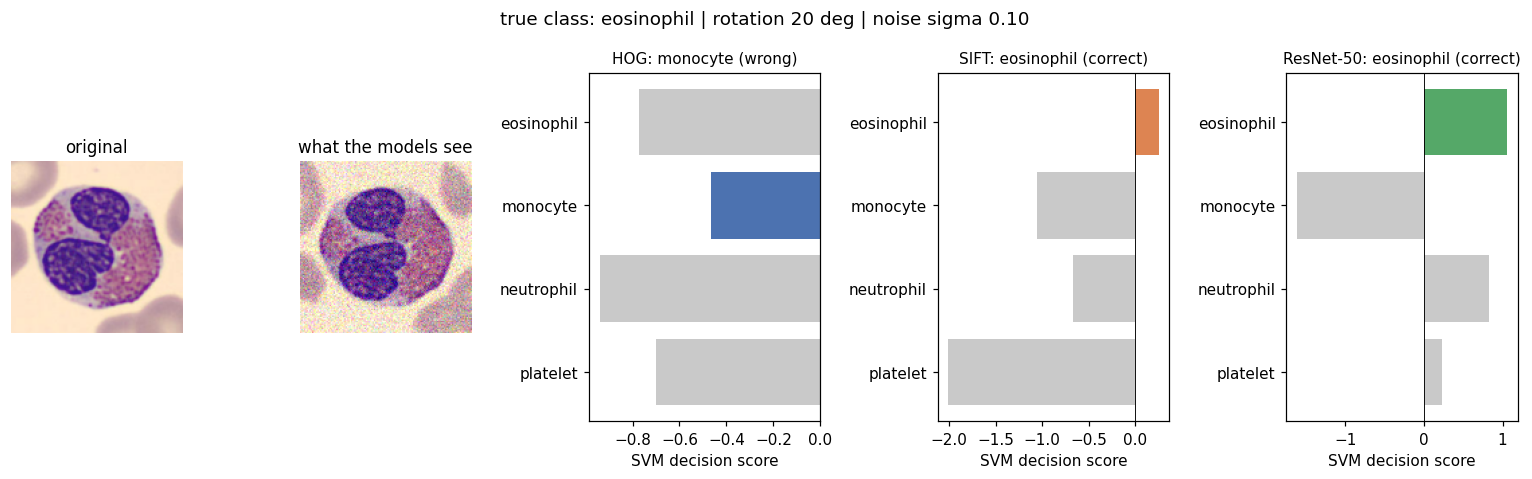

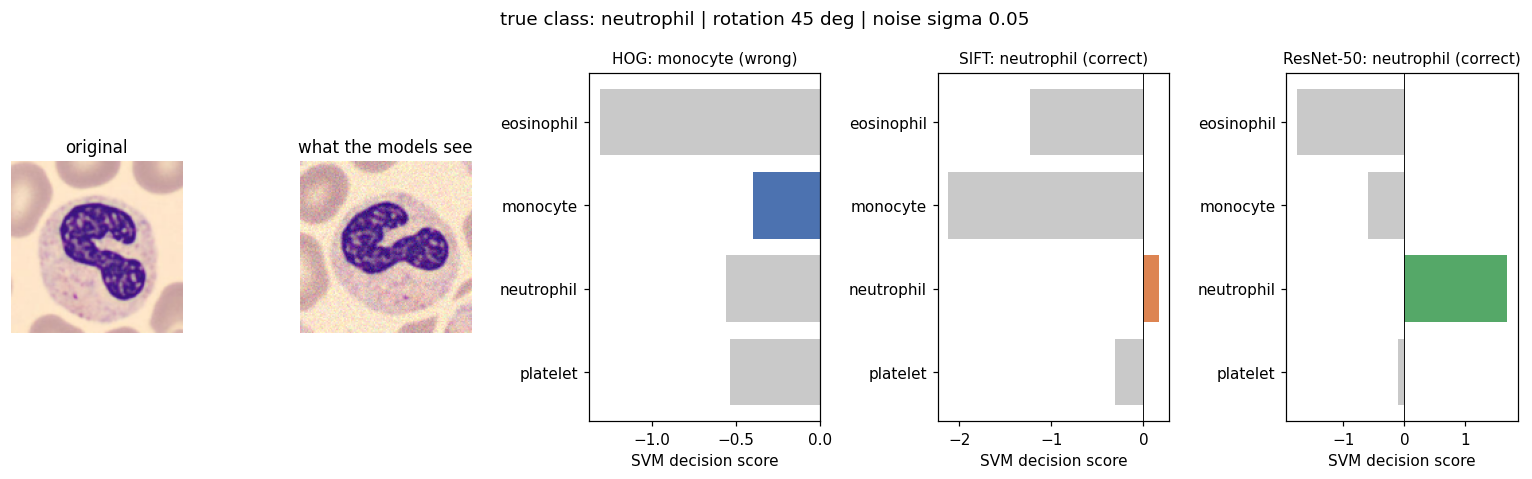

In [40]:
render(test_idx[0], ROT_DEG, 0.1)
render(test_idx[2], 45, NOISE_SIGMA)

### Bonus summary

In [41]:
order = acc3.mean(axis=1).sort_values(ascending=False)
ranking = ", ".join(f"{n} ({v:.1%})" for n, v in order.items())
loss = {n: (acc3.loc[n, "Noisy"] - acc3.loc[n, "Clean"]) * 100 for n in MODELS}
most_hurt = min(loss, key=loss.get)
colour_gap = (cnn_val_acc - cnn_gray_val) * 100
gap_text = (
    f"Removing colour cost ResNet-50 {colour_gap:.1f} points of validation accuracy"
    if colour_gap > 0
    else f"Removing colour changed ResNet-50 validation accuracy by {colour_gap:+.1f} points"
)
cost = ", ".join(f"{n} {results.loc[n, 'ms per image']:.1f} ms" for n in results.index)

display(
    Markdown(
        f"Ranking by mean test accuracy over the clean, rotated and noisy cases: {ranking}. "
        f"Noise hurt {most_hurt} most ({loss[most_hurt]:+.1f} points). "
        f"{gap_text}. "
        f"Feature-extraction time per image: {cost}."
    )
)

Ranking by mean test accuracy over the clean, rotated and noisy cases: ResNet-50 + SVM (bonus) (89.2%), SIFT + SVM (78.3%), HOG + SVM (64.7%). Noise hurt HOG + SVM most (-16.7 points). Removing colour cost ResNet-50 1.7 points of validation accuracy. Feature-extraction time per image: HOG + SVM 2.9 ms, SIFT + SVM 23.4 ms, ResNet-50 + SVM (bonus) 5.3 ms.

In [45]:
import base64
import json
import shutil
import subprocess
import sys
import time
import zipfile
from pathlib import Path

PACKAGE_RESULTS = True
NOTEBOOK_NAME = "FA23-BAI-039_Muhammad_Asad_Mashood_LabMid.ipynb"
NOTEBOOK_PATH = ""
RE_EXECUTE = False
PACKAGE_NAME = "FA23-BAI-039_LabMid_result"
TITLE_TEXT = "HOG vs SIFT on Blood-Cell Images"


def text_of(value):
    return "".join(value) if isinstance(value, list) else value


def fetch_live_notebook():
    try:
        from google.colab import _message
        reply = _message.blocking_request("get_ipynb", request="", timeout_sec=600)
        return reply["ipynb"] if reply else None
    except Exception:
        return None


def locate():
    if NOTEBOOK_PATH:
        return Path(NOTEBOOK_PATH).expanduser().resolve()
    roots = [Path.cwd(), Path("/content"), Path("/content/drive/MyDrive"), Path("/content/drive/MyDrive/Colab Notebooks"), Path.home()]
    found = []
    for root in roots:
        if root.is_dir():
            for p in root.glob("*.ipynb"):
                if not p.name.endswith("_to_run.ipynb") and TITLE_TEXT in p.read_text(encoding="utf-8", errors="ignore"):
                    found.append(p)
    if found:
        return max(found, key=lambda p: p.stat().st_mtime).resolve()
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("notebook file not found: set NOTEBOOK_PATH to the notebook file and run this cell again")
    print("could not read the live notebook and no saved copy was found, please upload the notebook (File > Download .ipynb)")
    uploaded = files.upload()
    return Path(next(iter(uploaded))).resolve()


def run_nbconvert(*args):
    done = subprocess.run([sys.executable, "-m", "nbconvert", *args], capture_output=True, text=True)
    if done.returncode != 0:
        print(done.stderr[-2500:])
        raise RuntimeError("nbconvert failed, see the message above")


start = time.time()
live = None if RE_EXECUTE else fetch_live_notebook()
if live is not None:
    print("read the outputs from the live notebook")
    source_path = Path.cwd() / NOTEBOOK_NAME
    raw = live
else:
    source_path = locate()
    print(f"using {source_path.name}")
    raw = json.loads(source_path.read_text(encoding="utf-8"))

workdir = source_path.parent
stem = source_path.stem
result_dir = workdir / PACKAGE_NAME
shutil.rmtree(result_dir, ignore_errors=True)
for sub in ("docs", "figures", "tables"):
    (result_dir / sub).mkdir(parents=True)

raw.get("metadata", {}).pop("widgets", None)
raw["cells"] = [c for c in raw["cells"] if "PACKAGE_RESULTS = True" not in text_of(c["source"])]
executed = result_dir / f"{stem}.ipynb"

if RE_EXECUTE:
    trimmed = workdir / f"{stem}_to_run.ipynb"
    trimmed.write_text(json.dumps(raw), encoding="utf-8")
    print("running the whole notebook in a fresh kernel, this can take several minutes on CPU ...")
    run_nbconvert(
        "--to", "notebook", "--execute", "--allow-errors", "--ExecutePreprocessor.timeout=7200",
        "--output", "executed_run", "--output-dir", str(result_dir), str(trimmed),
    )
    (result_dir / "executed_run.ipynb").replace(executed)
    trimmed.unlink()
else:
    executed.write_text(json.dumps(raw), encoding="utf-8")

run_nbconvert("--to", "markdown", "--output-dir", str(result_dir), str(executed))
run_nbconvert("--to", "html", "--output-dir", str(result_dir), str(executed))

executed_nb = json.loads(executed.read_text(encoding="utf-8"))
failed = [
    (i, o.get("ename"), o.get("evalue"))
    for i, c in enumerate(executed_nb["cells"]) if c["cell_type"] == "code"
    for o in c.get("outputs", []) if o["output_type"] == "error"
]

figure_count = 0
for i, cell in enumerate(executed_nb["cells"]):
    if cell["cell_type"] != "code":
        continue
    for o in cell.get("outputs", []):
        png = o.get("data", {}).get("image/png")
        if png:
            figure_count += 1
            (result_dir / "figures" / f"fig{figure_count:02d}_cell{i:02d}.png").write_bytes(base64.b64decode(text_of(png)))

table_names = []
try:
    import pandas as pd
except ImportError:
    pd = None
if pd is not None:
    for name, value in list(globals().items()):
        if isinstance(value, pd.DataFrame) and not name.startswith("_") and len(value) <= 200:
            value.to_csv(result_dir / "tables" / f"{name}.csv")
            table_names.append(name)
    grids, angles, sigmas = globals().get("heat"), globals().get("GRID_ANGLES"), globals().get("GRID_SIGMAS")
    if isinstance(grids, dict) and angles and sigmas:
        for model, grid in grids.items():
            label = model.split(" ")[0].lower()
            pd.DataFrame(grid * 100, index=sigmas, columns=angles).to_csv(result_dir / "tables" / f"rotation_noise_grid_{label}.csv")
            table_names.append(f"rotation_noise_grid_{label}")

blocks = ["# Results of the executed notebook\n", "Generated automatically from the printed outputs of every code cell. Figures are in the figures folder and in the Markdown and HTML exports, tables are in the tables folder.\n"]
for cell in executed_nb["cells"]:
    if cell["cell_type"] == "markdown":
        for line in text_of(cell["source"]).splitlines():
            if line.startswith("# "):
                blocks.append(f"## {line[2:].strip()}\n")
                break
        continue
    for o in cell.get("outputs", []):
        kind = o["output_type"]
        data = o.get("data", {})
        if kind == "stream":
            body = text_of(o["text"]).rstrip()
            if body:
                blocks.append("```text\n" + body + "\n```\n")
        elif kind in ("execute_result", "display_data") and "text/markdown" in data:
            blocks.append(text_of(data["text/markdown"]).strip() + "\n")
        elif kind in ("execute_result", "display_data") and set(data) == {"text/plain"}:
            blocks.append("```text\n" + text_of(data["text/plain"]).rstrip() + "\n```\n")
if failed:
    blocks.append("## Cells that raised errors\n")
    blocks.extend(f"- cell {i}: {name}: {value}\n" for i, name, value in failed)
(result_dir / "RESULTS.md").write_text("\n".join(blocks), encoding="utf-8")

readme = f"""# HOG vs SIFT vs ResNet-50 on Blood-Cell Images

Computer Vision lab mid exam (CSC455) by Muhammad Asad Mashood, FA23-BAI-039, COMSATS University Islamabad, Wah Campus.

Three classifiers are compared on four blood-cell types (eosinophil, monocyte, neutrophil, platelet) from BloodMNIST and tested for robustness to rotation and noise.

| Pipeline | Features | Classifier |
|---|---|---|
| HOG + SVM | Histogram of Oriented Gradients, 16 x 16 cells | LinearSVC |
| SIFT + SVM | SIFT descriptors on a fixed 6 x 6 keypoint grid | LinearSVC |
| ResNet-50 + SVM (bonus) | Pretrained ResNet-50 embeddings, colour, 128 px | LinearSVC |

Settings from registration number 039: seed 39, HOG cell 16 x 16, SIFT grid 6 x 6, 100 train, 30 validation and 30 test images per class, C chosen on the validation set only.

## Files

| File | Purpose |
|---|---|
| `{stem}.ipynb` | Notebook with all outputs |
| `{stem}.md` and `{stem}_files/` | Markdown version with all outputs and figures |
| `{stem}.html` | HTML version, print it to PDF for the PDF copy |
| `RESULTS.md` | Printed results of every section |
| `figures/` | Every figure of the notebook as a PNG file |
| `tables/` | Every result table as a CSV file |
| `dashboard.html` and `docs/index.html` | Interactive dashboard, publish `docs/` with GitHub Pages |
| `requirements.txt` | Python packages |
"""
(result_dir / "README.md").write_text(readme, encoding="utf-8")
(result_dir / "requirements.txt").write_text(
    "numpy\npandas\nmatplotlib\nopencv-python\nscikit-image\nscikit-learn\nmedmnist\ntorch\ntorchvision\nplotly\nipywidgets\njupyter\nnbconvert\n",
    encoding="utf-8",
)
(result_dir / ".gitignore").write_text("__pycache__/\n.ipynb_checkpoints/\n.DS_Store\n*.npz\n", encoding="utf-8")

dashboard = workdir / "dashboard.html"
if dashboard.exists() and (not RE_EXECUTE or dashboard.stat().st_mtime >= start):
    shutil.copy(dashboard, result_dir / "dashboard.html")
    shutil.copy(dashboard, result_dir / "docs" / "index.html")
else:
    print("dashboard.html was not found, run the Bonus section first")

zip_path = workdir / f"{PACKAGE_NAME}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(result_dir.rglob("*")):
        if p.is_file():
            z.write(p, Path(PACKAGE_NAME) / p.relative_to(result_dir))

print(f"packaged {sum(1 for p in result_dir.rglob('*') if p.is_file())} files in {time.time() - start:.0f} s -> {zip_path}")
print(f"figures saved: {figure_count} | tables saved: {len(table_names)} | cells with errors: {len(failed)}")
for i, name, value in failed:
    print(f"  cell {i}: {name}: {value}")

try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("open the zip from the folder shown above")

read the outputs from the live notebook
packaged 81 files in 34 s -> /content/FA23-BAI-039_LabMid_result.zip
figures saved: 28 | tables saved: 16 | cells with errors: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>